In [1]:


%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
python.exe -m pip install --upgrade pip

SyntaxError: invalid syntax (842801469.py, line 1)

In [3]:
pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [5]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


Label: 5


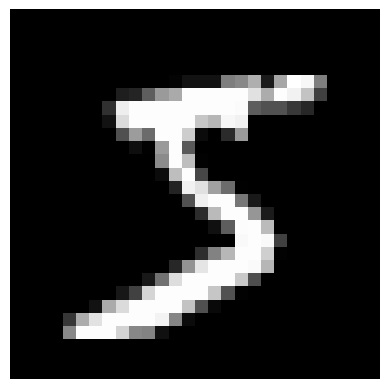

In [6]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0], cmap='gray')
print("Label:", y_train[0])
plt.axis('off')
plt.show()

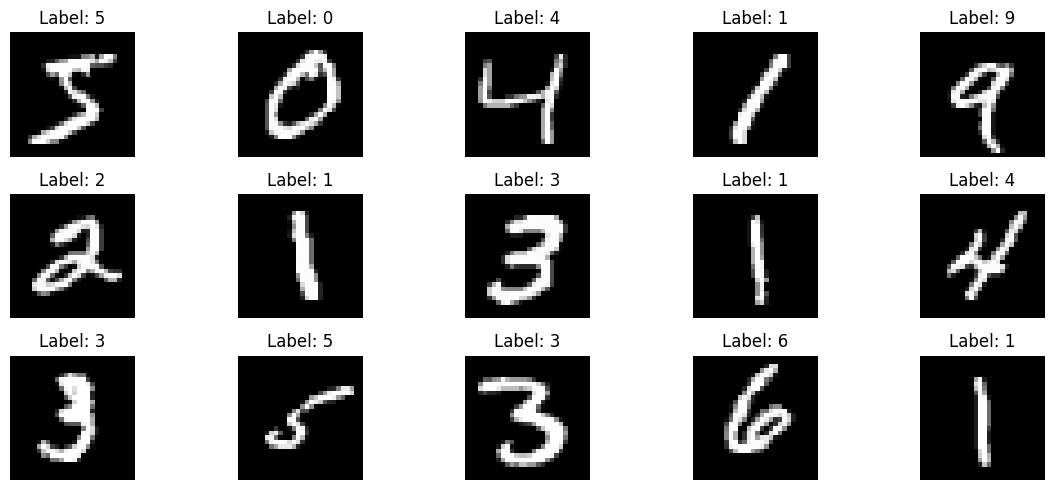

In [7]:
plt.figure(figsize=(12, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
import numpy as np

# Count occurrences of each digit
unique_digits, digit_counts = np.unique(y_train, return_counts=True)

# Display the results
for digit, count in zip(unique_digits, digit_counts):
    print(f"Digit {digit}: {count} images")

Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


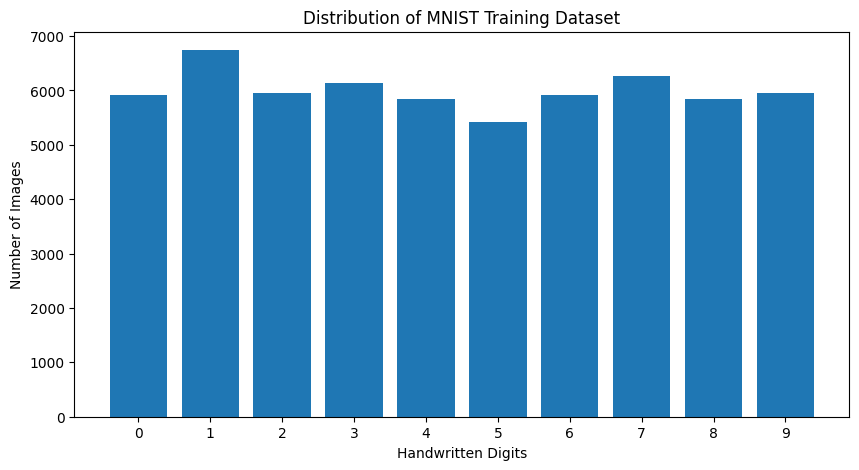

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(unique_digits, digit_counts)

plt.xlabel("Handwritten Digits")
plt.ylabel("Number of Images")
plt.title("Distribution of MNIST Training Dataset")

plt.xticks(unique_digits)

plt.show()

In [10]:
# Display the first image as numerical pixel values
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [11]:
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [12]:
print("Data type:", x_train.dtype)

Data type: uint8


In [13]:
# Normalize training images
x_train_normalized = x_train.astype('float32') / 255.0

# Normalize testing images
x_test_normalized = x_test.astype('float32') / 255.0

In [14]:
print("Training minimum:", x_train_normalized.min())
print("Training maximum:", x_train_normalized.max())

print("Testing minimum:", x_test_normalized.min())
print("Testing maximum:", x_test_normalized.max())

print("New data type:", x_train_normalized.dtype)

Training minimum: 0.0
Training maximum: 1.0
Testing minimum: 0.0
Testing maximum: 1.0
New data type: float32


In [15]:
# Flatten training images
x_train_flattened = x_train_normalized.reshape(60000, 784)

# Flatten testing images
x_test_flattened = x_test_normalized.reshape(10000, 784)

In [16]:
print("Original training shape:", x_train_normalized.shape)
print("Flattened training shape:", x_train_flattened.shape)

print("Original testing shape:", x_test_normalized.shape)
print("Flattened testing shape:", x_test_flattened.shape)

Original training shape: (60000, 28, 28)
Flattened training shape: (60000, 784)
Original testing shape: (10000, 28, 28)
Flattened testing shape: (10000, 784)


In [17]:
# Check training features
print("Training features shape:", x_train_flattened.shape)

# Check training labels
print("Training labels shape:", y_train.shape)

# Check testing features
print("Testing features shape:", x_test_flattened.shape)

# Check testing labels
print("Testing labels shape:", y_test.shape)

# Display the first 10 labels
print("First 10 labels:", y_train[:10])

# Find all unique classes
print("Unique classes:", np.unique(y_train))

Training features shape: (60000, 784)
Training labels shape: (60000,)
Testing features shape: (10000, 784)
Testing labels shape: (10000,)
First 10 labels: [5 0 4 1 9 2 1 3 1 4]
Unique classes: [0 1 2 3 4 5 6 7 8 9]


In [18]:
from sklearn.model_selection import train_test_split

# Split the original training dataset
X_train, X_val, y_train_split, y_val = train_test_split(
    x_train_flattened,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [19]:
print("Training features:", X_train.shape)
print("Training labels:", y_train_split.shape)

print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

print("Official testing features:", x_test_flattened.shape)
print("Official testing labels:", y_test.shape)

Training features: (48000, 784)
Training labels: (48000,)
Validation features: (12000, 784)
Validation labels: (12000,)
Official testing features: (10000, 784)
Official testing labels: (10000,)


In [20]:
from sklearn.model_selection import train_test_split

# Select 5,000 training examples
X_knn_train, _, y_knn_train, _ = train_test_split(
    X_train,
    y_train_split,
    train_size=5000,
    random_state=42,
    stratify=y_train_split
)

# Select 1,000 validation examples
X_knn_val, _, y_knn_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=1000,
    random_state=42,
    stratify=y_val
)

print("KNN training shape:", X_knn_train.shape)
print("KNN validation shape:", X_knn_val.shape)

KNN training shape: (5000, 784)
KNN validation shape: (1000, 784)


In [21]:
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=3)

In [22]:
import time

start_time = time.time()

knn_model.fit(X_knn_train, y_knn_train)

training_time = time.time() - start_time

print("Training completed!")
print("Training time:", training_time, "seconds")

Training completed!
Training time: 0.003996133804321289 seconds


In [23]:
start_time = time.time()

y_knn_pred = knn_model.predict(X_knn_val)

prediction_time = time.time() - start_time

print("Prediction completed!")
print("Prediction time:", prediction_time, "seconds")

Prediction completed!
Prediction time: 4.301796197891235 seconds


In [24]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_knn_val, y_knn_pred)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 92.4 %


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_knn_val, y_knn_pred))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96        99
           1       0.85      1.00      0.92       112
           2       0.98      0.81      0.88        99
           3       0.93      0.90      0.92       102
           4       0.95      0.92      0.93        97
           5       0.91      0.89      0.90        90
           6       0.95      0.97      0.96        99
           7       0.91      0.96      0.94       105
           8       0.95      0.88      0.91        98
           9       0.91      0.92      0.91        99

    accuracy                           0.92      1000
   macro avg       0.93      0.92      0.92      1000
weighted avg       0.93      0.92      0.92      1000



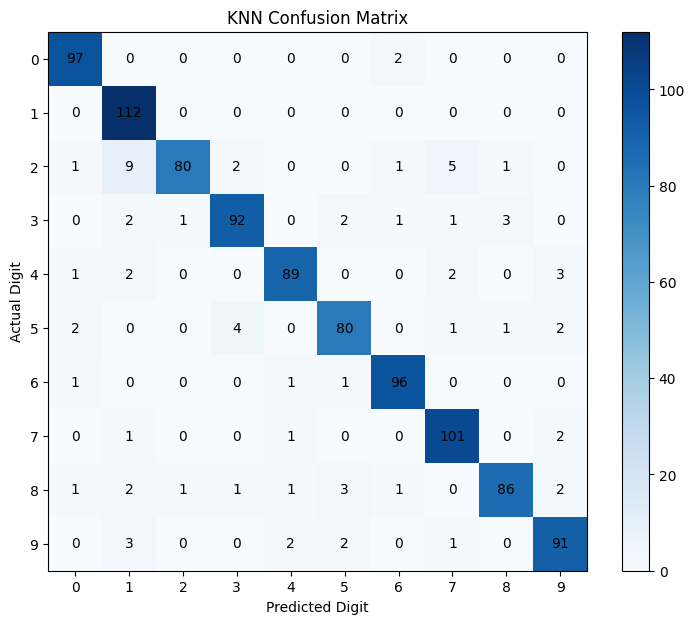

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_knn_val, y_knn_pred)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("KNN Confusion Matrix")

plt.xticks(range(10))
plt.yticks(range(10))

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

Total incorrect predictions: 76


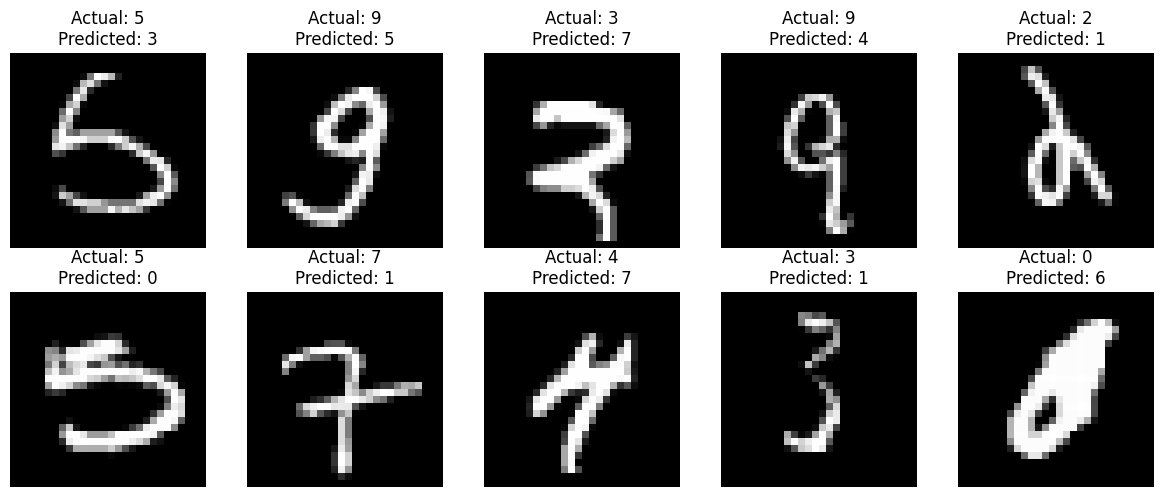

In [27]:
import numpy as np

# Find positions where actual and predicted labels differ
wrong_indices = np.where(y_knn_val != y_knn_pred)[0]

print("Total incorrect predictions:", len(wrong_indices))

# Display up to 10 incorrect predictions
plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)

    # Convert flattened image back to 28 x 28
    image = X_knn_val[index].reshape(28, 28)

    plt.imshow(image, cmap='gray')

    plt.title(
        f"Actual: {y_knn_val[index]}\nPredicted: {y_knn_pred[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

# Different K values to experiment with
k_values = [1, 3, 5, 7, 9]

# Store results
knn_results = []

for k in k_values:

    # Create KNN model
    model = KNeighborsClassifier(n_neighbors=k)

    # Measure training time
    start_time = time.time()
    model.fit(X_knn_train, y_knn_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X_knn_val)
    predict_time = time.time() - start_time

    # Calculate accuracy
    accuracy = accuracy_score(y_knn_val, predictions)

    # Save results
    knn_results.append({
        'K': k,
        'Accuracy': accuracy,
        'Training Time': train_time,
        'Prediction Time': predict_time
    })

    print(f"K={k}, Accuracy={accuracy * 100:.2f}%")

K=1, Accuracy=92.70%
K=3, Accuracy=92.40%
K=5, Accuracy=92.70%
K=7, Accuracy=92.80%
K=9, Accuracy=92.00%


In [29]:
import pandas as pd

knn_results_df = pd.DataFrame(knn_results)

print(knn_results_df)

   K  Accuracy  Training Time  Prediction Time
0  1     0.927       0.003851         0.122302
1  3     0.924       0.003859         0.090719
2  5     0.927       0.003145         0.103194
3  7     0.928       0.003389         0.100468
4  9     0.920       0.003250         0.098492


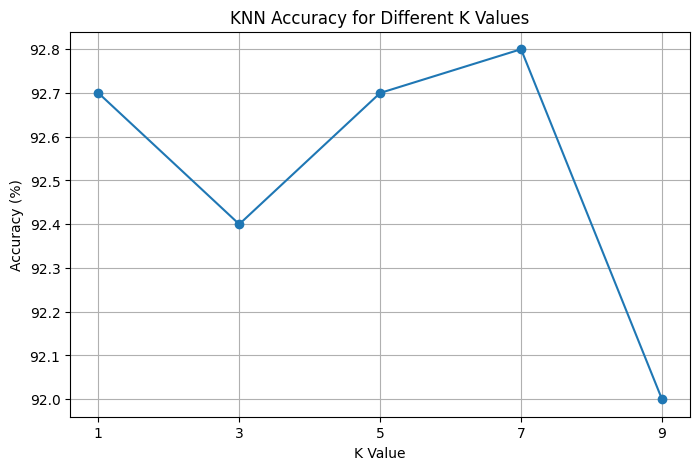

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_results_df['K'],
    knn_results_df['Accuracy'] * 100,
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Accuracy (%)")
plt.title("KNN Accuracy for Different K Values")

plt.xticks(k_values)
plt.grid(True)

plt.show()

### KNN Hyperparameter Tuning

We experimented with different values of K: 1, 3, 5, 7, and 9.

The highest validation accuracy was 92.8%, achieved with K = 7.

Therefore, K = 7 is selected as the best K value from these experiments.

The results also show that increasing K does not always improve accuracy.
The optimal value depends on the dataset and the relationship between
the training samples.

## USE SVM

In [31]:
from sklearn.model_selection import train_test_split

# Select 5,000 training images
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train,
    y_train_split,
    train_size=5000,
    random_state=42,
    stratify=y_train_split
)

# Select 1,000 validation images
X_svm_val, _, y_svm_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=1000,
    random_state=42,
    stratify=y_val
)

print("SVM Training shape:", X_svm_train.shape)
print("SVM Validation shape:", X_svm_val.shape)

SVM Training shape: (5000, 784)
SVM Validation shape: (1000, 784)


In [32]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

In [33]:
import time

start_time = time.time()

svm_model.fit(X_svm_train, y_svm_train)

svm_training_time = time.time() - start_time

print("SVM Training Time:", svm_training_time, "seconds")

SVM Training Time: 3.395034074783325 seconds


In [34]:
start_time = time.time()

y_svm_pred = svm_model.predict(X_svm_val)

svm_prediction_time = time.time() - start_time

print("SVM Prediction Time:", svm_prediction_time, "seconds")

SVM Prediction Time: 2.3461503982543945 seconds


In [35]:
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(y_svm_val, y_svm_pred)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 95.19999999999999 %


In [36]:
print("KNN Accuracy:", 92.8, "%")
print("SVM Accuracy:", svm_accuracy * 100, "%")

KNN Accuracy: 92.8 %
SVM Accuracy: 95.19999999999999 %


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_svm_val, y_svm_pred))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        99
           1       0.98      0.99      0.99       112
           2       0.96      0.94      0.95        99
           3       0.94      0.92      0.93       102
           4       0.95      0.93      0.94        97
           5       0.97      0.93      0.95        90
           6       0.95      0.97      0.96        99
           7       0.98      0.98      0.98       105
           8       0.89      0.94      0.92        98
           9       0.93      0.94      0.93        99

    accuracy                           0.95      1000
   macro avg       0.95      0.95      0.95      1000
weighted avg       0.95      0.95      0.95      1000



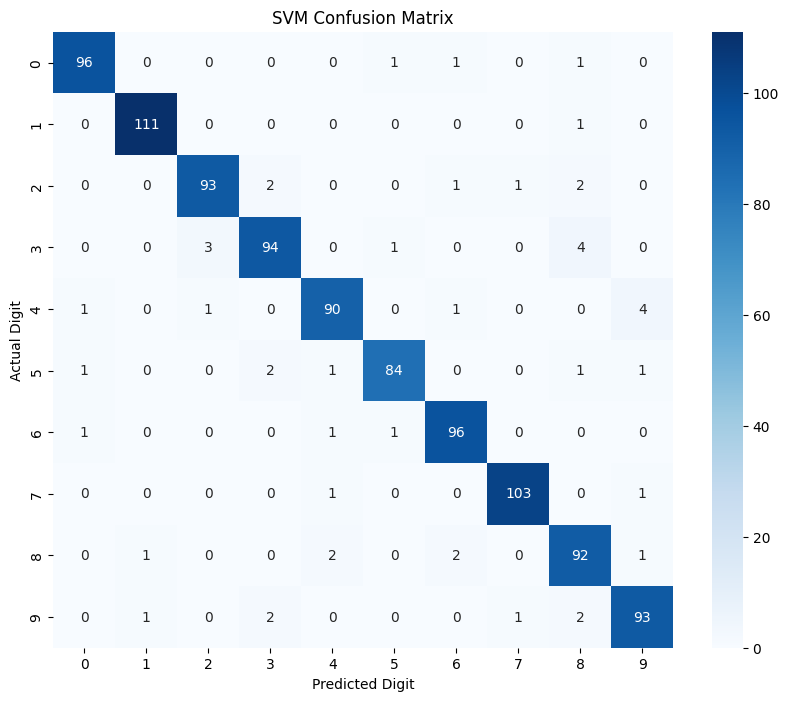

In [40]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

svm_cm = confusion_matrix(y_svm_val, y_svm_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("SVM Confusion Matrix")

plt.show()

Total incorrect predictions: 48


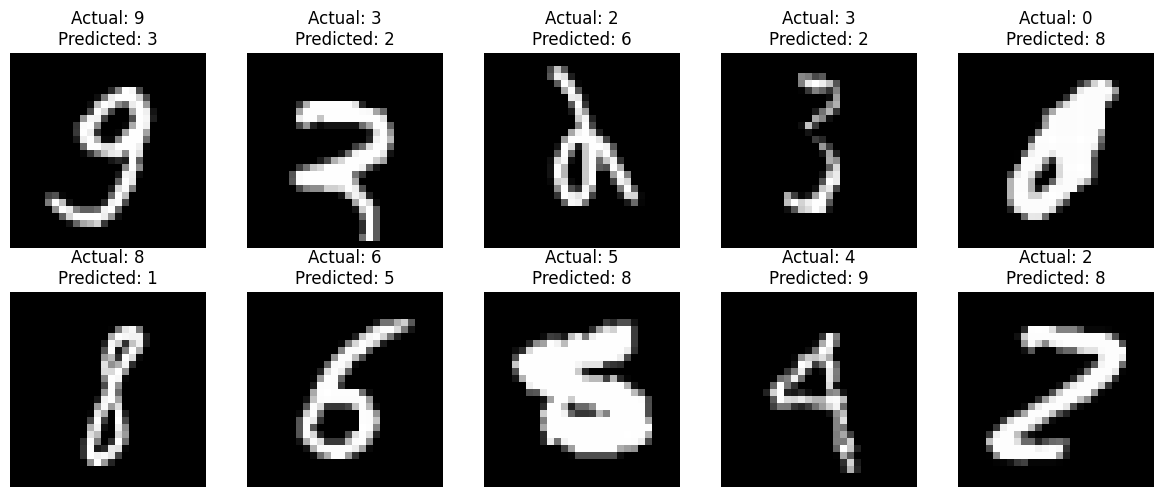

In [41]:
wrong_svm_indices = np.where(y_svm_val != y_svm_pred)[0]

print("Total incorrect predictions:", len(wrong_svm_indices))

plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_svm_indices[:10]):
    plt.subplot(2, 5, i + 1)

    image = X_svm_val[index].reshape(28, 28)

    plt.imshow(image, cmap='gray')

    plt.title(
        f"Actual: {y_svm_val[index]}\nPredicted: {y_svm_pred[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [42]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# Different C values
c_values = [0.1, 1, 10]

# Store experiment results
svm_results = []

for c in c_values:

    # Create SVM model
    model = SVC(
        kernel='rbf',
        C=c,
        gamma='scale'
    )

    # Measure training time
    start_time = time.time()
    model.fit(X_svm_train, y_svm_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X_svm_val)
    predict_time = time.time() - start_time

    # Calculate accuracy
    accuracy = accuracy_score(y_svm_val, predictions)

    # Store results
    svm_results.append({
        'C': c,
        'Accuracy': accuracy,
        'Training Time': train_time,
        'Prediction Time': predict_time
    })

    print(f"C={c}, Accuracy={accuracy * 100:.2f}%")

C=0.1, Accuracy=90.70%
C=1, Accuracy=95.20%
C=10, Accuracy=95.70%


In [43]:
import pandas as pd

svm_results_df = pd.DataFrame(svm_results)

print(svm_results_df)

      C  Accuracy  Training Time  Prediction Time
0   0.1     0.907       5.509761         3.267174
1   1.0     0.952       2.465023         3.000404
2  10.0     0.957       3.422518         2.173581


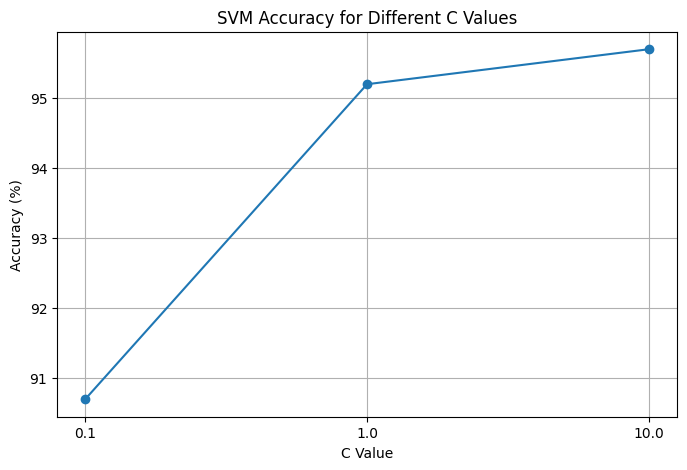

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    svm_results_df['C'].astype(str),
    svm_results_df['Accuracy'] * 100,
    marker='o'
)

plt.xlabel("C Value")
plt.ylabel("Accuracy (%)")
plt.title("SVM Accuracy for Different C Values")

plt.grid(True)
plt.show()

In [45]:
SVC(
    kernel='rbf',
    C=10,
    gamma='scale'
)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [46]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# Different gamma values
gamma_values = [0.001, 0.01, 0.1, 'scale']

# Store results
svm_gamma_results = []

for gamma in gamma_values:

    # Create SVM model
    model = SVC(
        kernel='rbf',
        C=10,
        gamma=gamma
    )

    # Measure training time
    start_time = time.time()
    model.fit(X_svm_train, y_svm_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X_svm_val)
    predict_time = time.time() - start_time

    # Calculate accuracy
    accuracy = accuracy_score(y_svm_val, predictions)

    # Store results
    svm_gamma_results.append({
        'Gamma': gamma,
        'Accuracy': accuracy,
        'Training Time': train_time,
        'Prediction Time': predict_time
    })

    print(f"Gamma={gamma}, Accuracy={accuracy * 100:.2f}%")

Gamma=0.001, Accuracy=93.40%
Gamma=0.01, Accuracy=95.60%
Gamma=0.1, Accuracy=85.40%
Gamma=scale, Accuracy=95.70%


In [47]:
svm_gamma_results_df = pd.DataFrame(svm_gamma_results)

print(svm_gamma_results_df)

   Gamma  Accuracy  Training Time  Prediction Time
0  0.001     0.934       2.497214         1.830988
1   0.01     0.956       2.206606         1.887426
2    0.1     0.854      14.618737         4.194846
3  scale     0.957       3.633213         2.434736


### SVM Hyperparameter Tuning

We experimented with different values of C and gamma using an RBF kernel.

C values tested: 0.1, 1, 10

Gamma values tested: 0.001, 0.01, 0.1, scale

The best tested configuration was:

- Kernel: RBF
- C: 10
- Gamma: scale
- Validation Accuracy: 95.7%

A low C value resulted in lower accuracy, while an excessively
high gamma value also reduced performance.

Therefore, C=10 and gamma='scale' were selected as the
best configuration among the tested combinations.

### Build a Logistic Regression classifier

In [50]:
from sklearn.model_selection import train_test_split

X_lr_train, _, y_lr_train, _ = train_test_split(
    X_train,
    y_train_split,
    train_size=5000,
    random_state=42,
    stratify=y_train_split
)

X_lr_val, _, y_lr_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=1000,
    random_state=42,
    stratify=y_val
)

print("Logistic Regression Training shape:", X_lr_train.shape)
print("Logistic Regression Validation shape:", X_lr_val.shape)

Logistic Regression Training shape: (5000, 784)
Logistic Regression Validation shape: (1000, 784)


In [51]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs'
)

In [52]:
import time

start_time = time.time()

lr_model.fit(X_lr_train, y_lr_train)

lr_training_time = time.time() - start_time

print("Logistic Regression Training Time:", lr_training_time, "seconds")

Logistic Regression Training Time: 2.170146942138672 seconds


In [53]:
start_time = time.time()

y_lr_pred = lr_model.predict(X_lr_val)

lr_prediction_time = time.time() - start_time

print("Logistic Regression Prediction Time:", lr_prediction_time, "seconds")

Logistic Regression Prediction Time: 0.0015153884887695312 seconds


In [54]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_lr_val, y_lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 89.7 %


In [55]:
print("KNN Accuracy:", 92.8, "%")
print("SVM Accuracy:", 95.7, "%")
print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

KNN Accuracy: 92.8 %
SVM Accuracy: 95.7 %
Logistic Regression Accuracy: 89.7 %


In [56]:
from sklearn.metrics import classification_report

print(classification_report(y_lr_val, y_lr_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92        99
           1       0.90      0.97      0.94       112
           2       0.88      0.82      0.85        99
           3       0.88      0.86      0.87       102
           4       0.94      0.91      0.92        97
           5       0.83      0.86      0.84        90
           6       0.90      0.91      0.90        99
           7       0.94      0.98      0.96       105
           8       0.87      0.84      0.85        98
           9       0.90      0.89      0.89        99

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000



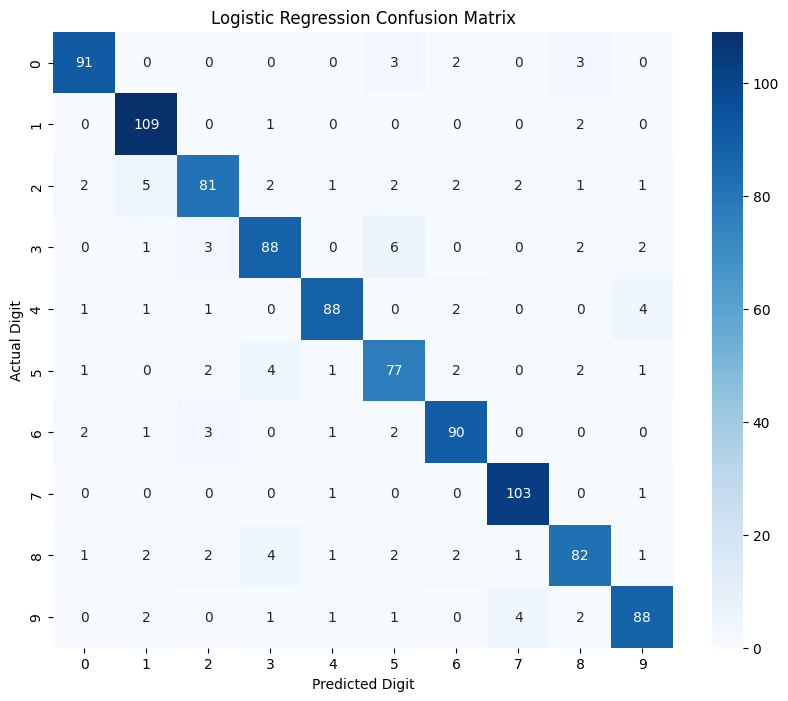

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

lr_cm = confusion_matrix(y_lr_val, y_lr_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

Total incorrect predictions: 103


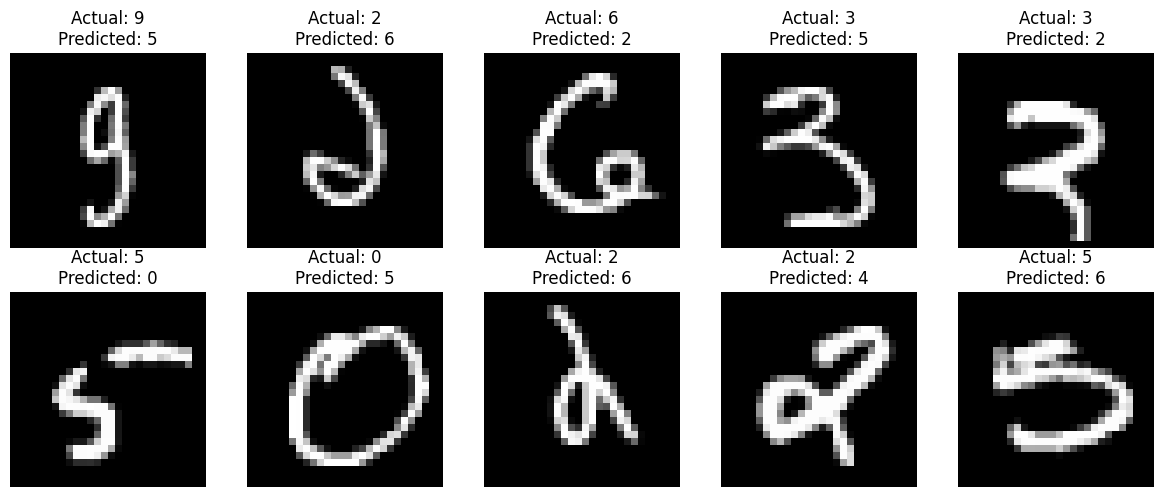

In [58]:
wrong_lr_indices = np.where(y_lr_val != y_lr_pred)[0]

print("Total incorrect predictions:", len(wrong_lr_indices))

plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_lr_indices[:10]):
    plt.subplot(2, 5, i + 1)

    image = X_lr_val[index].reshape(28, 28)

    plt.imshow(image, cmap='gray')

    plt.title(
        f"Actual: {y_lr_val[index]}\nPredicted: {y_lr_pred[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Different regularization values
C_values = [0.01, 0.1, 1, 10]

# Store experiment results
lr_results = []

for c in C_values:

    # Create Logistic Regression model
    model = LogisticRegression(
        C=c,
        max_iter=1000,
        solver='lbfgs'
    )

    # Measure training time
    start_time = time.time()
    model.fit(X_lr_train, y_lr_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X_lr_val)
    predict_time = time.time() - start_time

    # Calculate accuracy
    accuracy = accuracy_score(y_lr_val, predictions)

    # Store results
    lr_results.append({
        'C': c,
        'Accuracy': accuracy,
        'Training Time': train_time,
        'Prediction Time': predict_time
    })

    print(f"C={c}, Accuracy={accuracy * 100:.2f}%")

C=0.01, Accuracy=87.40%
C=0.1, Accuracy=90.10%
C=1, Accuracy=89.70%
C=10, Accuracy=89.00%


In [61]:
lr_results_df = pd.DataFrame(lr_results)

print(lr_results_df)

       C  Accuracy  Training Time  Prediction Time
0   0.01     0.874       1.934807         0.001398
1   0.10     0.901       2.434612         0.001804
2   1.00     0.897       3.411961         0.001570
3  10.00     0.890       4.408143         0.001223


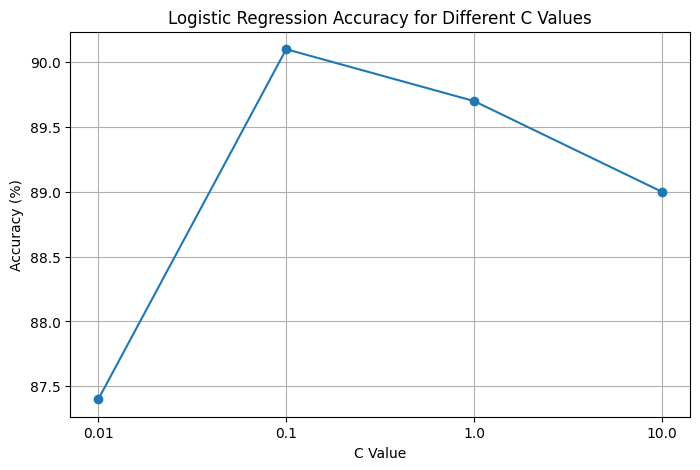

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    lr_results_df['C'].astype(str),
    lr_results_df['Accuracy'] * 100,
    marker='o'
)

plt.xlabel("C Value")
plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression Accuracy for Different C Values")

plt.grid(True)
plt.show()

### Logistic Regression Hyperparameter Tuning

We experimented with C values of 0.01, 0.1, 1, and 10.

The best validation accuracy was 90.1%, achieved with C = 0.1.

Stronger regularization at C = 0.01 reduced accuracy,
while weaker regularization at C = 1 and C = 10
also resulted in lower accuracy.

Therefore, C = 0.1 was selected as the best tested
configuration.

## Random classifier

In [63]:
from sklearn.model_selection import train_test_split

X_rf_train, _, y_rf_train, _ = train_test_split(
    X_train,
    y_train_split,
    train_size=5000,
    random_state=42,
    stratify=y_train_split
)

X_rf_val, _, y_rf_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=1000,
    random_state=42,
    stratify=y_val
)

print("Random Forest Training shape:", X_rf_train.shape)
print("Random Forest Validation shape:", X_rf_val.shape)

Random Forest Training shape: (5000, 784)
Random Forest Validation shape: (1000, 784)


In [64]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [65]:
import time

start_time = time.time()

rf_model.fit(X_rf_train, y_rf_train)

rf_training_time = time.time() - start_time

print("Random Forest Training Time:", rf_training_time, "seconds")

Random Forest Training Time: 0.891610860824585 seconds


In [66]:
start_time = time.time()

y_rf_pred = rf_model.predict(X_rf_val)

rf_prediction_time = time.time() - start_time

print("Random Forest Prediction Time:", rf_prediction_time, "seconds")

Random Forest Prediction Time: 0.04068803787231445 seconds


In [67]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_rf_val, y_rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 93.4 %


In [68]:
print("KNN Accuracy:", 92.8, "%")
print("SVM Accuracy:", 95.7, "%")
print("Logistic Regression Accuracy:", 90.1, "%")
print("Random Forest Accuracy:", rf_accuracy * 100, "%")

KNN Accuracy: 92.8 %
SVM Accuracy: 95.7 %
Logistic Regression Accuracy: 90.1 %
Random Forest Accuracy: 93.4 %


In [69]:
from sklearn.metrics import classification_report

print(classification_report(y_rf_val, y_rf_pred))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96        99
           1       0.95      0.99      0.97       112
           2       0.97      0.92      0.94        99
           3       0.90      0.89      0.90       102
           4       0.97      0.90      0.93        97
           5       0.95      0.91      0.93        90
           6       0.95      0.96      0.95        99
           7       0.94      0.96      0.95       105
           8       0.89      0.92      0.90        98
           9       0.88      0.91      0.90        99

    accuracy                           0.93      1000
   macro avg       0.93      0.93      0.93      1000
weighted avg       0.93      0.93      0.93      1000



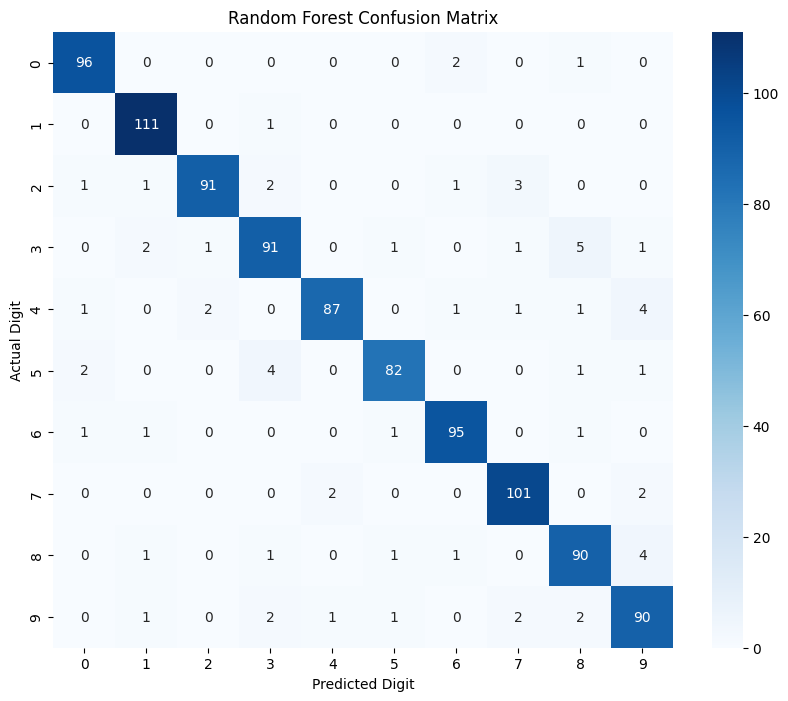

In [70]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

rf_cm = confusion_matrix(y_rf_val, y_rf_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Random Forest Confusion Matrix")

plt.show()

Total incorrect predictions: 66


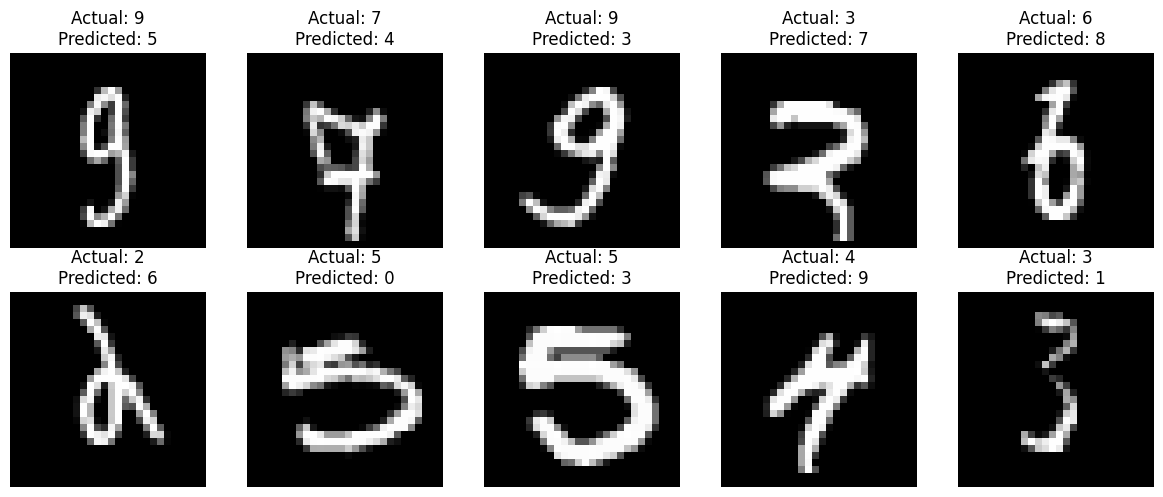

In [71]:
wrong_rf_indices = np.where(y_rf_val != y_rf_pred)[0]

print("Total incorrect predictions:", len(wrong_rf_indices))

plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_rf_indices[:10]):
    plt.subplot(2, 5, i + 1)

    image = X_rf_val[index].reshape(28, 28)

    plt.imshow(image, cmap='gray')

    plt.title(
        f"Actual: {y_rf_val[index]}\nPredicted: {y_rf_pred[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [72]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

n_estimators_values = [50, 100, 200]

rf_results = []

for n in n_estimators_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_rf_train, y_rf_train)
    training_time = time.time() - start_time

    start_time = time.time()
    predictions = model.predict(X_rf_val)
    prediction_time = time.time() - start_time

    accuracy = accuracy_score(y_rf_val, predictions)

    rf_results.append({
        'Number of Trees': n,
        'Accuracy': accuracy,
        'Training Time': training_time,
        'Prediction Time': prediction_time
    })

    print(f"Trees: {n}, Accuracy: {accuracy * 100:.2f}%")

Trees: 50, Accuracy: 92.70%
Trees: 100, Accuracy: 93.40%
Trees: 200, Accuracy: 93.70%


In [73]:
import pandas as pd

rf_tuning_df = pd.DataFrame(rf_results)

rf_tuning_df

,Number of Trees,Accuracy,Training Time,Prediction Time
0,50,0.927,0.317031,0.028949
1,100,0.934,0.815193,0.072255
2,200,0.937,2.514741,0.158561


In [74]:
depth_values = [None, 10, 20, 30]

depth_results = []

for depth in depth_values:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_rf_train, y_rf_train)
    training_time = time.time() - start_time

    start_time = time.time()
    predictions = model.predict(X_rf_val)
    prediction_time = time.time() - start_time

    accuracy = accuracy_score(y_rf_val, predictions)

    depth_results.append({
        'Max Depth': depth,
        'Accuracy': accuracy,
        'Training Time': training_time,
        'Prediction Time': prediction_time
    })

    print(f"Depth: {depth}, Accuracy: {accuracy * 100:.2f}%")

Depth: None, Accuracy: 93.70%
Depth: 10, Accuracy: 92.10%
Depth: 20, Accuracy: 93.70%
Depth: 30, Accuracy: 93.70%


In [75]:
depth_tuning_df = pd.DataFrame(depth_results)

depth_tuning_df

,Max Depth,Accuracy,Training Time,Prediction Time
0,NaN,0.937,2.062268,0.138592
1,10.0,0.921,1.586403,0.131342
2,20.0,0.937,2.499356,0.133035
3,30.0,0.937,2.172719,0.111617


In [76]:
split_values = [2, 5, 10, 20]

split_results = []

for split in split_values:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=split,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_rf_train, y_rf_train)
    training_time = time.time() - start_time

    start_time = time.time()
    predictions = model.predict(X_rf_val)
    prediction_time = time.time() - start_time

    accuracy = accuracy_score(y_rf_val, predictions)

    split_results.append({
        'Min Samples Split': split,
        'Accuracy': accuracy,
        'Training Time': training_time,
        'Prediction Time': prediction_time
    })

    print(f"Min Samples Split: {split}, Accuracy: {accuracy * 100:.2f}%")

Min Samples Split: 2, Accuracy: 93.70%
Min Samples Split: 5, Accuracy: 93.00%
Min Samples Split: 10, Accuracy: 92.70%
Min Samples Split: 20, Accuracy: 92.40%


In [77]:
split_tuning_df = pd.DataFrame(split_results)

split_tuning_df

,Min Samples Split,Accuracy,Training Time,Prediction Time
0,2,0.937,1.308185,0.124288
1,5,0.930,2.030756,0.120086
2,10,0.927,2.119933,0.179493
3,20,0.924,2.120652,0.130042


## Next algorithm: Artificial Neural Network (ANN)
We've completed four classical machine-learning approaches:
1. KNN
2. SVM
3. Logistic Regression
4. Random Forest

In [78]:
X_train_images, X_val_images, y_train_nn, y_val_nn = train_test_split(
    x_train_normalized,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [79]:
print("Training images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)
print("Training labels:", y_train_nn.shape)
print("Validation labels:", y_val_nn.shape)

Training images: (48000, 28, 28)
Validation images: (12000, 28, 28)
Training labels: (48000,)
Validation labels: (12000,)


In [80]:
X_train_ann = X_train_images.reshape(48000, 784)
X_val_ann = X_val_images.reshape(12000, 784)

In [81]:
print("ANN Training Data:", X_train_ann.shape)
print("ANN Validation Data:", X_val_ann.shape)

ANN Training Data: (48000, 784)
ANN Validation Data: (12000, 784)


In [86]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

ann_model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
ann_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [87]:
ann_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [88]:
history = ann_model.fit(
    X_train_ann,
    y_train_nn,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_ann, y_val_nn)
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9229 - loss: 0.2642 - val_accuracy: 0.9578 - val_loss: 0.1391
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9666 - loss: 0.1118 - val_accuracy: 0.9657 - val_loss: 0.1148
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9774 - loss: 0.0729 - val_accuracy: 0.9691 - val_loss: 0.1074
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9835 - loss: 0.0526 - val_accuracy: 0.9713 - val_loss: 0.1020
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9871 - loss: 0.0408 - val_accuracy: 0.9708 - val_loss: 0.1048
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9896 - loss: 0.0327 - val_accuracy: 0.9729 - val_loss: 0.1055
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9921 - loss: 0.0245 - val_accuracy: 0.9707 - val_loss: 0.1160
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9919 - loss: 0.0239 - 

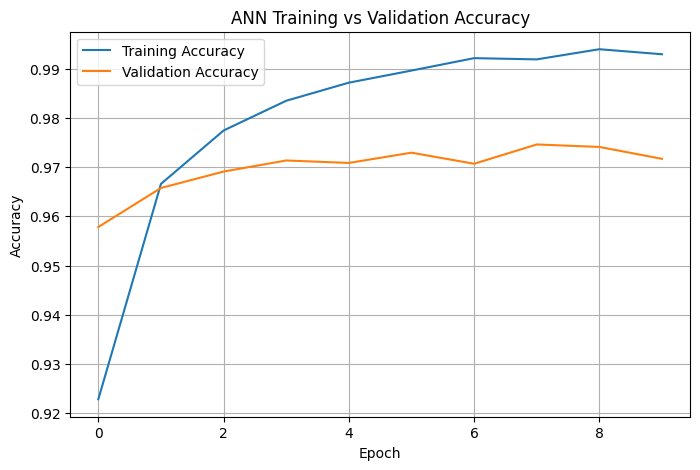

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

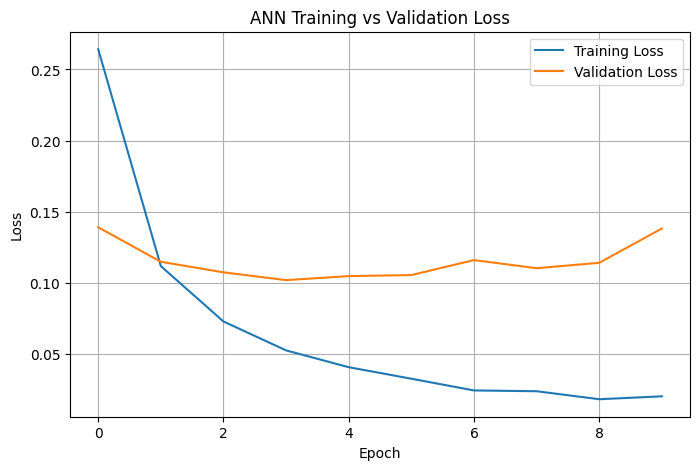

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [91]:
ann_predictions = ann_model.predict(X_val_ann)

ann_predicted_labels = ann_predictions.argmax(axis=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [92]:
from sklearn.metrics import accuracy_score

ann_accuracy = accuracy_score(
    y_val_nn,
    ann_predicted_labels
)

print("ANN Validation Accuracy:", ann_accuracy * 100)

ANN Validation Accuracy: 97.16666666666667


In [93]:
from sklearn.metrics import classification_report

print(classification_report(y_val_nn, ann_predicted_labels))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1185
           1       0.98      0.99      0.99      1348
           2       0.96      0.98      0.97      1192
           3       0.97      0.96      0.96      1226
           4       0.97      0.98      0.97      1168
           5       0.94      0.98      0.96      1084
           6       0.99      0.98      0.99      1184
           7       0.98      0.98      0.98      1253
           8       0.97      0.93      0.95      1170
           9       0.98      0.94      0.96      1190

    accuracy                           0.97     12000
   macro avg       0.97      0.97      0.97     12000
weighted avg       0.97      0.97      0.97     12000



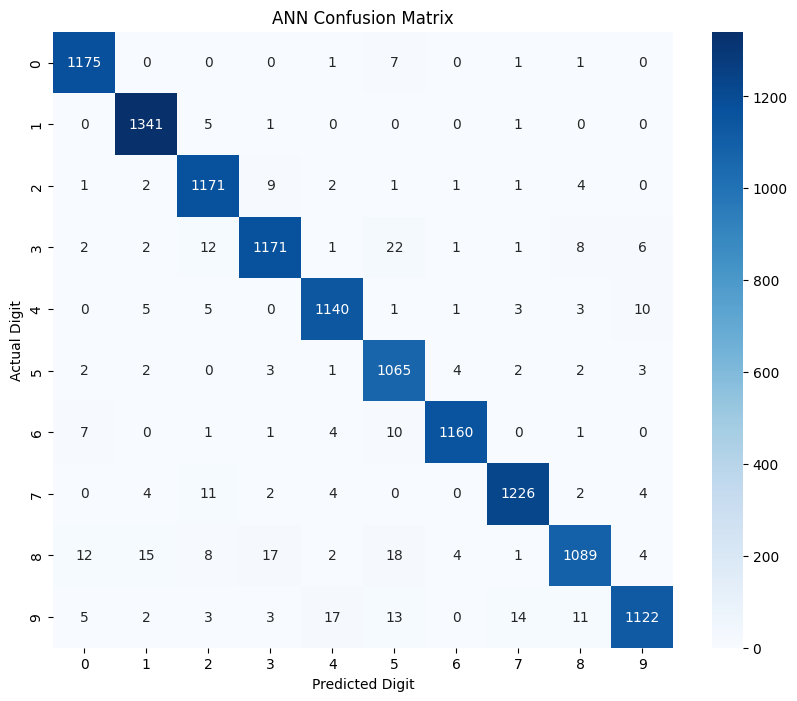

In [94]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

ann_cm = confusion_matrix(y_val_nn, ann_predicted_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(ann_cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("ANN Confusion Matrix")

plt.show()

In [95]:
from tensorflow.keras.callbacks import EarlyStopping

In [96]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [97]:
ann_model_es = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

ann_model_es.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [101]:
history_es = ann_model_es.fit(
    X_train_ann,
    y_train_nn,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_ann, y_val_nn),
    callbacks=[early_stopping]
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9888 - loss: 0.0330 - val_accuracy: 0.9755 - val_loss: 0.0962
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9907 - loss: 0.0277 - val_accuracy: 0.9739 - val_loss: 0.1049
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9921 - loss: 0.0220 - val_accuracy: 0.9722 - val_loss: 0.1192


In [102]:
ann_es_loss, ann_es_accuracy = ann_model_es.evaluate(
    X_val_ann,
    y_val_nn,
    verbose=0
)

print("Early Stopping ANN Accuracy:", ann_es_accuracy * 100)
print("Early Stopping ANN Loss:", ann_es_loss)

Early Stopping ANN Accuracy: 97.54999876022339
Early Stopping ANN Loss: 0.09618812799453735


## Convolutional Neural Network (CNN).

In [103]:
X_train_cnn = X_train_images.reshape(48000, 28, 28, 1)

X_val_cnn = X_val_images.reshape(12000, 28, 28, 1)

x_test_cnn = x_test_normalized.reshape(10000, 28, 28, 1)

In [104]:
print("CNN Training Data:", X_train_cnn.shape)
print("CNN Validation Data:", X_val_cnn.shape)
print("CNN Test Data:", x_test_cnn.shape)

CNN Training Data: (48000, 28, 28, 1)
CNN Validation Data: (12000, 28, 28, 1)
CNN Test Data: (10000, 28, 28, 1)


In [105]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

In [106]:
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

In [107]:

cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [108]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [109]:
cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train_nn,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_cnn, y_val_nn)
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9480 - loss: 0.1696 - val_accuracy: 0.9797 - val_loss: 0.0667
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9839 - loss: 0.0525 - val_accuracy: 0.9845 - val_loss: 0.0521
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9892 - loss: 0.0358 - val_accuracy: 0.9864 - val_loss: 0.0484
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9922 - loss: 0.0260 - val_accuracy: 0.9878 - val_loss: 0.0439
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9947 - loss: 0.0180 - val_accuracy: 0.9872 - val_loss: 0.0470
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9958 - loss: 0.0140 - val_accuracy: 0.9866 - val_loss: 0.0469
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9965 - loss: 0.0118 - val_accuracy: 0.9891 - val_loss: 0.0454
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9968 -

In [110]:
cnn_predictions = cnn_model.predict(X_val_cnn)

cnn_predicted_labels = cnn_predictions.argmax(axis=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [111]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_nn,
    cnn_predicted_labels
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1185
           1       0.99      1.00      0.99      1348
           2       0.99      0.98      0.99      1192
           3       1.00      0.97      0.99      1226
           4       0.99      0.99      0.99      1168
           5       0.98      0.99      0.98      1084
           6       0.99      0.99      0.99      1184
           7       0.99      0.99      0.99      1253
           8       0.98      0.98      0.98      1170
           9       0.99      0.99      0.99      1190

    accuracy                           0.99     12000
   macro avg       0.99      0.99      0.99     12000
weighted avg       0.99      0.99      0.99     12000



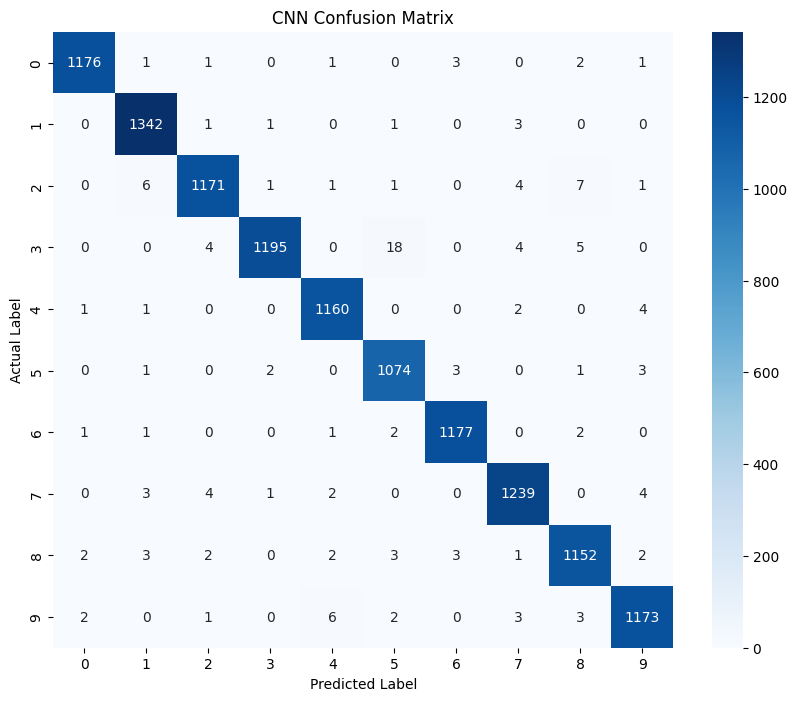

In [112]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cnn_cm = confusion_matrix(
    y_val_nn,
    cnn_predicted_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

plt.show()

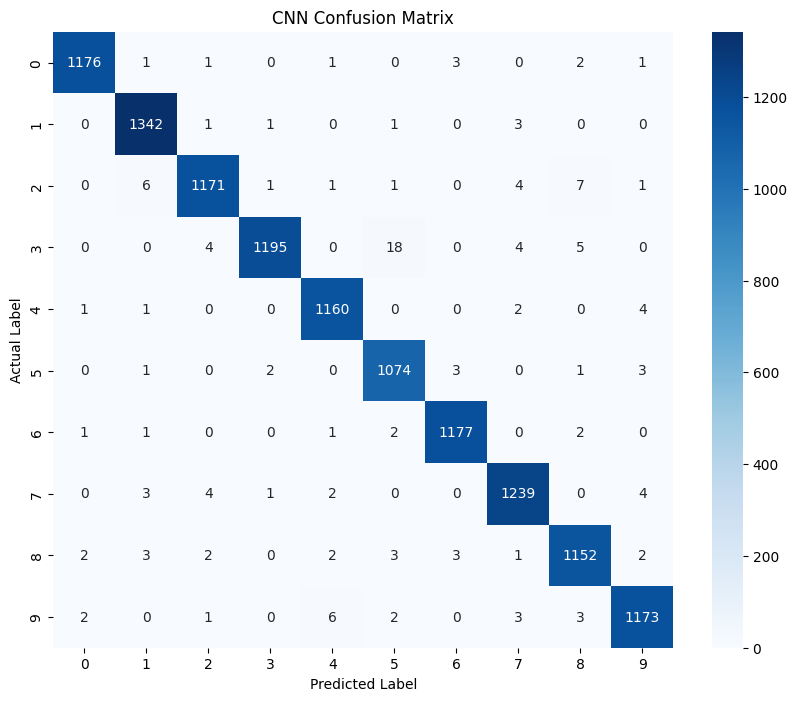

In [113]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

plt.show()

In [114]:
import numpy as np

incorrect_indices = np.where(
    cnn_predicted_labels != y_val_nn
)[0]

print("Total incorrect predictions:", len(incorrect_indices))

Total incorrect predictions: 141


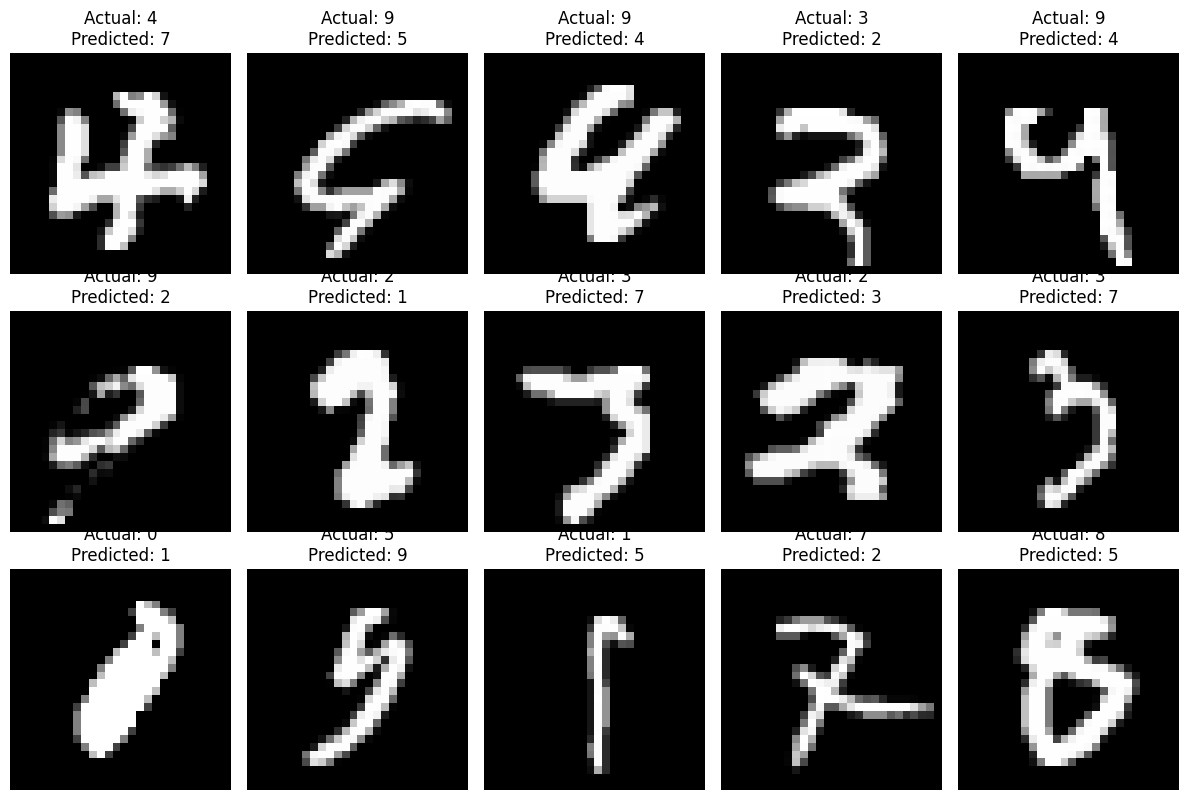

In [115]:
plt.figure(figsize=(12, 8))

for i, index in enumerate(incorrect_indices[:15]):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_val_images[index], cmap='gray')

    plt.title(
        f"Actual: {y_val_nn[index]}\n"
        f"Predicted: {cnn_predicted_labels[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [116]:
import pandas as pd

mistakes_df = pd.DataFrame({
    'Actual': y_val_nn[incorrect_indices],
    'Predicted': cnn_predicted_labels[incorrect_indices]
})

mistake_counts = (
    mistakes_df
    .value_counts()
    .reset_index(name='Count')
    .sort_values('Count', ascending=False)
)

print(mistake_counts)

    Actual  Predicted  Count
0        3          5     18
1        2          8      7
2        9          4      6
3        2          1      6
4        3          8      5
5        3          2      4
6        3          7      4
7        7          2      4
8        4          9      4
9        7          9      4
10       2          7      4
11       5          9      3
12       8          5      3
13       9          7      3
14       8          1      3
15       0          6      3
16       7          1      3
17       9          8      3
18       8          6      3
19       5          6      3
20       1          7      3
21       4          7      2
22       9          5      2
23       8          9      2
24       7          4      2
25       8          4      2
26       5          3      2
27       0          8      2
28       6          8      2
29       8          2      2
30       9          0      2
31       6          5      2
32       8          0      2
33       9    

Number of 3 predicted as 5: 18


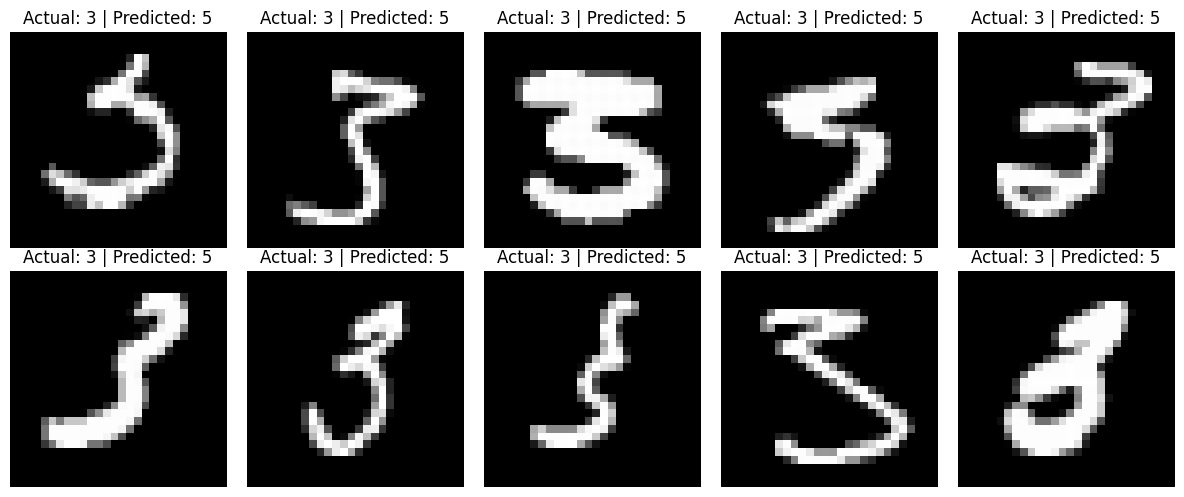

In [117]:
# Find images where actual digit is 3
# but the CNN predicted 5

confused_indices = np.where(
    (y_val_nn == 3) &
    (cnn_predicted_labels == 5)
)[0]

print("Number of 3 predicted as 5:", len(confused_indices))

plt.figure(figsize=(12, 5))

for i, index in enumerate(confused_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_val_images[index], cmap='gray')

    plt.title("Actual: 3 | Predicted: 5")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [118]:
from tensorflow.keras.callbacks import EarlyStopping

cnn_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [119]:
cnn_model_es = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [120]:
cnn_model_es.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [121]:
cnn_history_es = cnn_model_es.fit(
    X_train_cnn,
    y_train_nn,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_cnn, y_val_nn),
    callbacks=[cnn_early_stopping]
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9528 - loss: 0.1570 - val_accuracy: 0.9796 - val_loss: 0.0680
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9846 - loss: 0.0516 - val_accuracy: 0.9844 - val_loss: 0.0536
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9899 - loss: 0.0343 - val_accuracy: 0.9867 - val_loss: 0.0471
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9930 - loss: 0.0236 - val_accuracy: 0.9872 - val_loss: 0.0516
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9948 - loss: 0.0178 - val_accuracy: 0.9872 - val_loss: 0.0525


In [122]:
cnn_es_loss, cnn_es_accuracy = cnn_model_es.evaluate(
    X_val_cnn,
    y_val_nn,
    verbose=0
)

print("Early Stopping CNN Accuracy:", cnn_es_accuracy * 100)
print("Early Stopping CNN Loss:", cnn_es_loss)

Early Stopping CNN Accuracy: 98.66666793823242
Early Stopping CNN Loss: 0.047092925757169724


## COMPARING MODELS

In [123]:
from sklearn.model_selection import train_test_split

X_compare_train, X_compare_val, y_compare_train, y_compare_val = train_test_split(
    X_train,
    y_train_split,
    train_size=5000,
    test_size=1000,
    random_state=42,
    stratify=y_train_split
)

print("Comparison Training Data:", X_compare_train.shape)
print("Comparison Validation Data:", X_compare_val.shape)

Comparison Training Data: (5000, 784)
Comparison Validation Data: (1000, 784)


In [124]:
from sklearn.neighbors import KNeighborsClassifier
import time

knn_compare = KNeighborsClassifier(n_neighbors=7)

start_time = time.time()

knn_compare.fit(
    X_compare_train,
    y_compare_train
)

knn_train_time = time.time() - start_time

start_time = time.time()

knn_compare_predictions = knn_compare.predict(
    X_compare_val
)

knn_prediction_time = time.time() - start_time

In [125]:
from sklearn.metrics import accuracy_score

knn_compare_accuracy = accuracy_score(
    y_compare_val,
    knn_compare_predictions
)

print("KNN Accuracy:", knn_compare_accuracy * 100)
print("Training Time:", knn_train_time)
print("Prediction Time:", knn_prediction_time)

KNN Accuracy: 92.60000000000001
Training Time: 0.004734039306640625
Prediction Time: 0.11242532730102539


In [126]:
from sklearn.svm import SVC

svm_compare = SVC(
    kernel='rbf',
    C=10,
    gamma='scale'
)

start_time = time.time()

svm_compare.fit(
    X_compare_train,
    y_compare_train
)

svm_train_time = time.time() - start_time

start_time = time.time()

svm_compare_predictions = svm_compare.predict(
    X_compare_val
)

svm_prediction_time = time.time() - start_time

In [127]:
svm_compare_accuracy = accuracy_score(
    y_compare_val,
    svm_compare_predictions
)

print("SVM Accuracy:", svm_compare_accuracy * 100)
print("Training Time:", svm_train_time)
print("Prediction Time:", svm_prediction_time)

SVM Accuracy: 94.39999999999999
Training Time: 3.2611868381500244
Prediction Time: 3.090202569961548


In [128]:
from sklearn.linear_model import LogisticRegression

lr_compare = LogisticRegression(
    C=0.1,
    max_iter=1000,
    solver='lbfgs'
)

start_time = time.time()

lr_compare.fit(
    X_compare_train,
    y_compare_train
)

lr_train_time = time.time() - start_time

start_time = time.time()

lr_compare_predictions = lr_compare.predict(
    X_compare_val
)

lr_prediction_time = time.time() - start_time

In [129]:
lr_compare_accuracy = accuracy_score(
    y_compare_val,
    lr_compare_predictions
)

print("Logistic Regression Accuracy:", lr_compare_accuracy * 100)
print("Training Time:", lr_train_time)
print("Prediction Time:", lr_prediction_time)

Logistic Regression Accuracy: 89.0
Training Time: 1.9919664859771729
Prediction Time: 0.004417896270751953


In [130]:
from sklearn.ensemble import RandomForestClassifier

rf_compare = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_compare.fit(
    X_compare_train,
    y_compare_train
)

rf_train_time = time.time() - start_time

start_time = time.time()

rf_compare_predictions = rf_compare.predict(
    X_compare_val
)

rf_prediction_time = time.time() - start_time

In [131]:
rf_compare_accuracy = accuracy_score(
    y_compare_val,
    rf_compare_predictions
)

print("Random Forest Accuracy:", rf_compare_accuracy * 100)
print("Training Time:", rf_train_time)
print("Prediction Time:", rf_prediction_time)

Random Forest Accuracy: 93.2
Training Time: 1.677624225616455
Prediction Time: 0.12243771553039551


In [132]:
ann_compare = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [133]:
ann_compare.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [134]:
start_time = time.time()

ann_compare_history = ann_compare.fit(
    X_compare_train,
    y_compare_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_compare_val, y_compare_val)
)

ann_train_time = time.time() - start_time

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7918 - loss: 0.7358 - val_accuracy: 0.8800 - val_loss: 0.4322
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9142 - loss: 0.2937 - val_accuracy: 0.8970 - val_loss: 0.3568
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9362 - loss: 0.2104 - val_accuracy: 0.9040 - val_loss: 0.3211
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9536 - loss: 0.1594 - val_accuracy: 0.9060 - val_loss: 0.3025
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9656 - loss: 0.1200 - val_accuracy: 0.9090 - val_loss: 0.2976
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9784 - loss: 0.0894 - val_accuracy: 0.9080 - val_loss: 0.3051
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9856 - loss: 0.0652 - val_accuracy: 0.9150 - val_loss: 0.2992
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9920 - loss: 0.0454 - val_accuracy: 0

In [135]:
start_time = time.time()

ann_compare_predictions = ann_compare.predict(
    X_compare_val
).argmax(axis=1)

ann_prediction_time = time.time() - start_time

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [136]:
ann_compare_accuracy = accuracy_score(
    y_compare_val,
    ann_compare_predictions
)

print("ANN Accuracy:", ann_compare_accuracy * 100)
print("Training Time:", ann_train_time)
print("Prediction Time:", ann_prediction_time)

ANN Accuracy: 92.60000000000001
Training Time: 10.245477437973022
Prediction Time: 0.22074675559997559


In [137]:
X_compare_train_cnn = X_compare_train.reshape(5000, 28, 28, 1)

X_compare_val_cnn = X_compare_val.reshape(1000, 28, 28, 1)

print("CNN Comparison Training:", X_compare_train_cnn.shape)
print("CNN Comparison Validation:", X_compare_val_cnn.shape)

CNN Comparison Training: (5000, 28, 28, 1)
CNN Comparison Validation: (1000, 28, 28, 1)


In [138]:
cnn_compare = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [139]:
cnn_compare.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [140]:
start_time = time.time()

cnn_compare_history = cnn_compare.fit(
    X_compare_train_cnn,
    y_compare_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_compare_val_cnn, y_compare_val)
)

cnn_train_time = time.time() - start_time

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8016 - loss: 0.6407 - val_accuracy: 0.9140 - val_loss: 0.2830
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9460 - loss: 0.1767 - val_accuracy: 0.9340 - val_loss: 0.1945
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9630 - loss: 0.1096 - val_accuracy: 0.9450 - val_loss: 0.1697
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9748 - loss: 0.0790 - val_accuracy: 0.9480 - val_loss: 0.1568
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9804 - loss: 0.0625 - val_accuracy: 0.9580 - val_loss: 0.1549
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9838 - loss: 0.0478 - val_accuracy: 0.9580 - val_loss: 0.1524
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9896 - loss: 0.0327 - val_accuracy: 0.9610 - val_loss: 0.1542
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9938 - loss: 0.0239 - val_accu

In [141]:
start_time = time.time()

cnn_compare_predictions = cnn_compare.predict(
    X_compare_val_cnn
).argmax(axis=1)

cnn_prediction_time = time.time() - start_time

cnn_compare_accuracy = accuracy_score(
    y_compare_val,
    cnn_compare_predictions
)

print("CNN Accuracy:", cnn_compare_accuracy * 100)
print("Training Time:", cnn_train_time)
print("Prediction Time:", cnn_prediction_time)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
CNN Accuracy: 95.3
Training Time: 23.174659252166748
Prediction Time: 0.4757068157196045


## What have we learned?
- CNN: Highest accuracy. It can learn spatial patterns and features directly from images.
- SVM: Strong accuracy with substantially less training time than CNN in this experiment.
- Random Forest: Good balance between accuracy and prediction speed.
- KNN: Very fast training, but prediction requires distance calculations.
- ANN: Learns nonlinear patterns but doesn't explicitly preserve image structure.
- Logistic Regression: Fast prediction, but lowest accuracy.
Two important conclusions
1. CNN is our current accuracy winner at 95.30%.
2. Our original full-data CNN achieved 98.92%, suggesting that CNN benefits significantly from more training examples.
We should not yet call CNN the final production winner. We still need to evaluate the models under the final testing procedure.

In [142]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    'KNN': knn_compare_predictions,
    'SVM': svm_compare_predictions,
    'Logistic Regression': lr_compare_predictions,
    'Random Forest': rf_compare_predictions,
    'ANN': ann_compare_predictions,
    'CNN': cnn_compare_predictions
}

comparison_results = []

for model_name, predictions in models.items():

    comparison_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_compare_val, predictions),
        'Precision': precision_score(
            y_compare_val, predictions, average='weighted'
        ),
        'Recall': recall_score(
            y_compare_val, predictions, average='weighted'
        ),
        'F1 Score': f1_score(
            y_compare_val, predictions, average='weighted'
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0                  KNN     0.926     0.9281   0.926    0.9257
1                  SVM     0.944     0.9448   0.944    0.9441
2  Logistic Regression     0.890     0.8902   0.890    0.8895
3        Random Forest     0.932     0.9325   0.932    0.9319
4                  ANN     0.926     0.9273   0.926    0.9261
5                  CNN     0.953     0.9549   0.953    0.9530


In [143]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("CNN Test Accuracy:", cnn_test_accuracy * 100)
print("CNN Test Loss:", cnn_test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9906 - loss: 0.0456
CNN Test Accuracy: 99.05999898910522
CNN Test Loss: 0.04564289376139641


In [144]:
# Generate predictions for all 10,000 test images
cnn_test_predictions = cnn_model.predict(x_test_cnn)

# Convert probability outputs into digit labels
cnn_test_predicted_labels = cnn_test_predictions.argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [145]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    cnn_test_predicted_labels
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.98      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.98      1.00      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



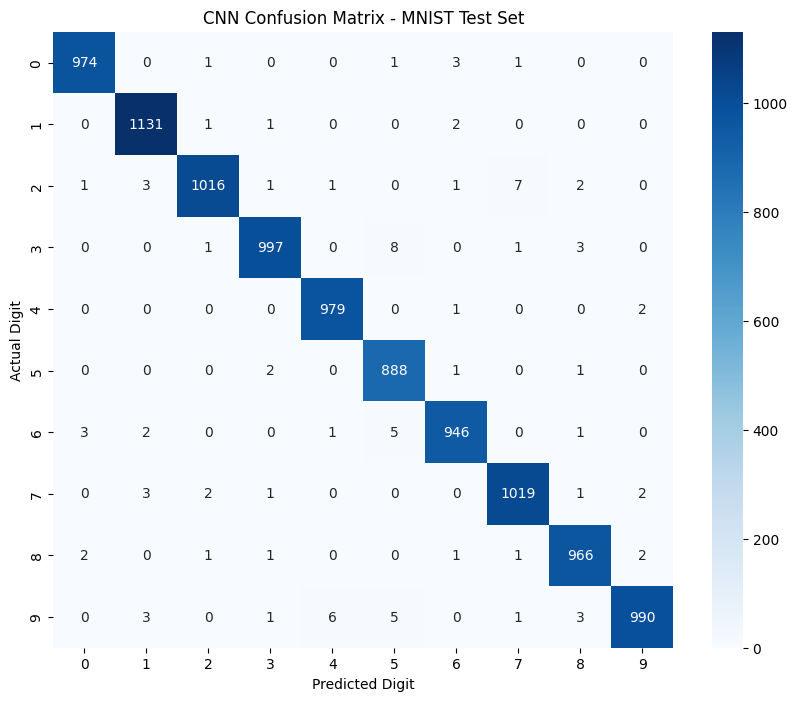

In [146]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cnn_confusion_matrix = confusion_matrix(
    y_test,
    cnn_test_predicted_labels
)

# Visualize it
plt.figure(figsize=(10, 8))

sns.heatmap(
    cnn_confusion_matrix,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("CNN Confusion Matrix - MNIST Test Set")

plt.show()

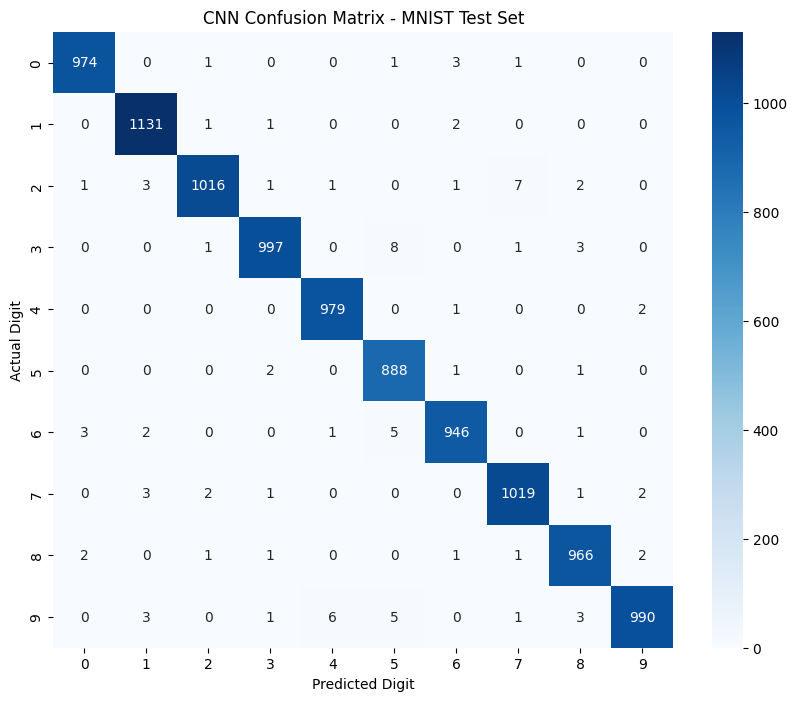

In [147]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cnn_confusion_matrix = confusion_matrix(
    y_test,
    cnn_test_predicted_labels
)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cnn_confusion_matrix,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("CNN Confusion Matrix - MNIST Test Set")

plt.show()

In [148]:
# Print the confusion matrix as numbers
print(cnn_confusion_matrix)

# Count total incorrect predictions
total_errors = len(y_test) - cnn_confusion_matrix.trace()

print("\nTotal incorrect predictions:", total_errors)

# Find the most common misclassifications
for actual_digit in range(10):
    for predicted_digit in range(10):

        if actual_digit != predicted_digit:
            errors = cnn_confusion_matrix[actual_digit, predicted_digit]

            if errors > 0:
                print(
                    f"Actual {actual_digit} predicted as "
                    f"{predicted_digit}: {errors}"
                )

[[ 974    0    1    0    0    1    3    1    0    0]
 [   0 1131    1    1    0    0    2    0    0    0]
 [   1    3 1016    1    1    0    1    7    2    0]
 [   0    0    1  997    0    8    0    1    3    0]
 [   0    0    0    0  979    0    1    0    0    2]
 [   0    0    0    2    0  888    1    0    1    0]
 [   3    2    0    0    1    5  946    0    1    0]
 [   0    3    2    1    0    0    0 1019    1    2]
 [   2    0    1    1    0    0    1    1  966    2]
 [   0    3    0    1    6    5    0    1    3  990]]

Total incorrect predictions: 94
Actual 0 predicted as 2: 1
Actual 0 predicted as 5: 1
Actual 0 predicted as 6: 3
Actual 0 predicted as 7: 1
Actual 1 predicted as 2: 1
Actual 1 predicted as 3: 1
Actual 1 predicted as 6: 2
Actual 2 predicted as 0: 1
Actual 2 predicted as 1: 3
Actual 2 predicted as 3: 1
Actual 2 predicted as 4: 1
Actual 2 predicted as 6: 1
Actual 2 predicted as 7: 7
Actual 2 predicted as 8: 2
Actual 3 predicted as 2: 1
Actual 3 predicted as 5: 8
Actu

In [149]:
# Save the trained CNN model
cnn_model.save("mnist_cnn_model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


## Later, we can reload it without training again:
from tensorflow.keras.models import load_model

loaded_cnn_model = load_model("mnist_cnn_model.keras")

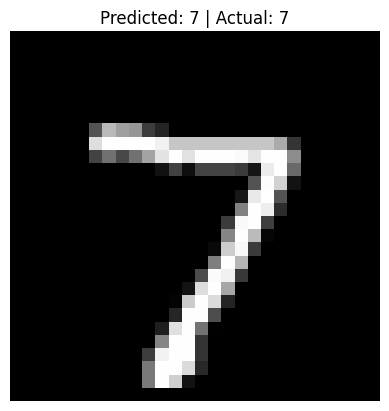

Predicted digit: 7
Actual digit: 7
Confidence: 100.0 %


In [151]:
import numpy as np
import matplotlib.pyplot as plt

# Select one image from the test dataset
image_index = 0

# Get the image
sample_image = x_test_cnn[image_index]

# Make a prediction
prediction = cnn_model.predict(
    sample_image.reshape(1, 28, 28, 1),
    verbose=0
)

# Get the predicted digit
predicted_digit = np.argmax(prediction)

# Get the actual digit
actual_digit = y_test[image_index]

# Display the image and results
plt.imshow(sample_image.squeeze(), cmap='gray')
plt.title(
    f"Predicted: {predicted_digit} | Actual: {actual_digit}"
)
plt.axis('off')
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", actual_digit)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

# Handwritten Digits Recognition Using Machine Learning and Deep Learning

## 1. Project Overview

### 1.1 Introduction

Handwritten Digit Recognition is a computer vision and machine learning project that focuses on identifying handwritten numerical digits from images.

The objective of this project is to develop a classification system capable of recognizing digits from 0 to 9 using the MNIST (Modified National Institute of Standards and Technology) dataset.

The project explores traditional machine learning algorithms as well as artificial neural networks and convolutional neural networks to identify the most effective classification approach.

### 1.2 Problem Statement

Handwritten digits can vary significantly in shape, size, thickness, orientation and writing style. This makes automatic recognition a challenging classification problem.

The goal is to build a model that can accurately classify a given handwritten digit image into one of ten categories (0–9).

### 1.3 Project Objectives

- Understand and explore the MNIST handwritten digits dataset.
- Perform data preprocessing and normalization.
- Analyze the distribution of handwritten digit classes.
- Develop multiple machine learning and deep learning models.
- Compare models using accuracy, precision, recall and F1-score.
- Identify the best-performing classification model.
- Evaluate the selected model using unseen test data.
- Analyze incorrect predictions and classification challenges.
- Recommend a suitable model for practical deployment.

### 1.4 Technologies and Libraries Used

- Python
- Jupyter Notebook
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- TensorFlow / Keras

## 2. Dataset Description and Exploratory Data Analysis

### 2.1 Dataset Description

The MNIST dataset is a widely used benchmark dataset for handwritten digit recognition.

It contains 70,000 grayscale images of handwritten digits ranging from 0 to 9.

The dataset is divided into:

| Dataset | Number of Images |
|---|---:|
| Training dataset | 60,000 |
| Testing dataset | 10,000 |
| Total | 70,000 |

Each image has the following properties:

- Image dimensions: 28 × 28 pixels
- Image type: Grayscale
- Pixel value range: 0–255
- Number of classes: 10 (digits 0–9)
- Number of pixels per image: 784

### 2.2 Dataset Loading

The MNIST dataset was loaded using TensorFlow Keras.

The training dataset contains 60,000 images and their corresponding labels, while the test dataset contains 10,000 images and their labels.

### 2.3 Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the dataset's structure, image characteristics and class distribution.

The following activities were performed:

1. Examined the dimensions and shapes of the training and testing datasets.
2. Inspected image data types and pixel value ranges.
3. Visualized individual handwritten digit images.
4. Displayed multiple sample images to understand variations in handwriting.
5. Analyzed the distribution of all ten digit classes.

### 2.4 Class Distribution Analysis

The training dataset contains the following number of images for each digit:

| Digit | Number of Images |
|---|---:|
| 0 | 5,923 |
| 1 | 6,742 |
| 2 | 5,958 |
| 3 | 6,131 |
| 4 | 5,842 |
| 5 | 5,421 |
| 6 | 5,918 |
| 7 | 6,265 |
| 8 | 5,851 |
| 9 | 5,949 |

### 2.5 EDA Findings

- The dataset contains 60,000 training images and 10,000 test images.
- All images are grayscale and have dimensions of 28 × 28 pixels.
- The dataset contains ten classification categories.
- The class distribution is reasonably balanced.
- Digit 1 has the highest number of training samples, while digit 5 has the lowest.
- Handwriting variations make digit recognition a challenging classification task.

**Conclusion:** The dataset is suitable for developing and evaluating multiclass handwritten digit classification models.

## 3. Data Preprocessing

Data preprocessing is an essential step in machine learning. It prepares raw data in a suitable format for model training and evaluation.

The following preprocessing techniques were applied to the MNIST dataset.

### 3.1 Pixel Normalization

The original MNIST images contain pixel values ranging from 0 to 255.

These values were converted into floating-point numbers and normalized to a range between 0 and 1 by dividing each pixel value by 255.

**Reason:**

- Reduces the numerical range of input features.
- Helps neural networks learn more efficiently.
- Improves numerical stability during training.

### 3.2 Image Flattening for Traditional Machine Learning Models

Traditional machine learning algorithms such as KNN, SVM, Logistic Regression and Random Forest require input data in a two-dimensional tabular format.

Therefore, each 28 × 28 image was converted into a one-dimensional array containing 784 pixel values.

**Transformation:**

28 × 28 pixels → 784 features

This representation was used for the traditional machine learning models and the ANN.

### 3.3 Train-Validation Split

The original training dataset of 60,000 images was divided into two subsets:

| Subset | Number of Images | Percentage |
|---|---:|---:|
| Training | 48,000 | 80% |
| Validation | 12,000 | 20% |

The split was performed using stratified sampling to maintain approximately the same class distribution in both subsets.

A random state of 42 was used to ensure reproducibility.

### 3.4 Preserving Image Dimensions for CNN

Unlike traditional machine learning algorithms, Convolutional Neural Networks can learn spatial patterns directly from images.

Therefore, the image dimensions were preserved as 28 × 28 pixels, with an additional channel dimension.

**Input shape:**

28 × 28 × 1

The additional dimension represents the single grayscale channel.

### 3.5 Official Test Dataset

The separate MNIST test dataset containing 10,000 images was kept untouched during training, model selection and validation.

It was used only for the final evaluation of the selected full-data CNN model.

### 3.6 Preprocessing Summary

| Model | Input Representation |
|---|---|
| KNN | 784 flattened features |
| SVM | 784 flattened features |
| Logistic Regression | 784 flattened features |
| Random Forest | 784 flattened features |
| ANN | 784 flattened features |
| CNN | 28 × 28 × 1 image |

**Conclusion:** Normalization and appropriate input formatting prepared the dataset for both traditional machine learning algorithms and deep learning architectures.

## 4. Model Development and Experimentation

Six classification algorithms were implemented and evaluated to identify the most effective approach for handwritten digit recognition.

The models were divided into two categories:

**Traditional Machine Learning**
1. K-Nearest Neighbors (KNN)
2. Support Vector Machine (SVM)
3. Logistic Regression
4. Random Forest Classifier

**Deep Learning**
5. Artificial Neural Network (ANN)
6. Convolutional Neural Network (CNN)

### 4.1 K-Nearest Neighbors (KNN)

KNN is a supervised machine learning algorithm that classifies a data point based on the majority class of its nearest neighboring data points.

For handwritten digit recognition, KNN compares the pixel values of an input image with previously observed images.

**Configuration and experimentation:**

- Distance-based classification algorithm.
- Different values of K were evaluated.
- Tested K values: 1, 3, 5, 7 and 9.
- Best tested configuration: K = 7.
- Best exploratory validation accuracy: 92.8%.

**Advantages:**
- Simple to understand and implement.
- Does not require a complex training process.
- Useful as a baseline classification model.

**Limitations:**
- Prediction can become computationally expensive with larger datasets.
- Performance depends on the choice of K and distance metric.
- Stores training data for prediction.

### 4.2 Support Vector Machine (SVM)

SVM is a supervised learning algorithm that identifies an optimal decision boundary (hyperplane) to separate different classes.

An RBF (Radial Basis Function) kernel was used because handwritten digit patterns may have nonlinear relationships.

**Configuration and experimentation:**

- Kernel: RBF.
- C values tested: 0.1, 1 and 10.
- Gamma values tested: 0.001, 0.01, 0.1 and scale.
- Best tested configuration: C = 10, gamma = scale.
- Best exploratory validation accuracy: 95.7%.

**Advantages:**
- Effective for complex classification problems.
- Can model nonlinear decision boundaries.
- Achieved strong performance among traditional machine learning models.

**Limitations:**
- Training can be computationally expensive on larger datasets.
- Parameter selection can significantly affect performance.
- Prediction time can increase with the number of support vectors.

### 4.3 Logistic Regression

Logistic Regression is a supervised classification algorithm that estimates the probability of an input belonging to different classes.

Although its name contains regression, it is commonly used for classification tasks.

For this project, multiclass classification was performed using the softmax-based multinomial approach.

**Configuration and experimentation:**

- Solver: LBFGS.
- Maximum iterations: 1000.
- Different regularization strengths (C) were evaluated.
- Tested C values: 0.01, 0.1, 1 and 10.
- Best tested configuration: C = 0.1.
- Best exploratory validation accuracy: 90.1%.

**Advantages:**
- Simple and computationally efficient at prediction time.
- Provides a useful baseline.
- Relatively easy to interpret compared with complex neural networks.

**Limitations:**
- Uses a linear decision boundary in the input feature space.
- May struggle to capture complex visual patterns.
- Achieved lower accuracy than the other leading models.

### 4.4 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve classification performance.

Each tree produces a prediction, and the final class is determined through majority voting.

**Configuration and experimentation:**

- Number of estimators tested: 50, 100 and 200.
- Maximum depth values tested: None, 10, 20 and 30.
- Minimum samples split values tested: 2, 5, 10 and 20.
- Best tested configuration:
  - n_estimators = 200
  - max_depth = None
  - min_samples_split = 2
  - random_state = 42
- Best exploratory validation accuracy: 93.7%.

**Advantages:**
- Handles nonlinear relationships.
- Combines multiple decision trees.
- Generally robust to individual noisy features.

**Limitations:**
- Can require considerable memory.
- Model complexity increases with the number of trees.
- Does not naturally exploit the spatial structure of images.

### 4.5 Artificial Neural Network (ANN)

An Artificial Neural Network is a deep learning model inspired by the interconnected structure of biological neurons.

The ANN consists of an input layer, hidden layers and an output layer.

For this project, each 28 × 28 image was flattened into 784 input features.

**Architecture:**

- Input layer: 784 neurons.
- Hidden layer 1: 128 neurons, ReLU activation.
- Hidden layer 2: 64 neurons, ReLU activation.
- Output layer: 10 neurons, Softmax activation.

**Training configuration:**

- Optimizer: Adam.
- Loss function: Sparse Categorical Crossentropy.
- Evaluation metric: Accuracy.
- Epochs: 10.
- Batch size: 32.
- Total trainable parameters: 109,386.

The model achieved a best validation accuracy of approximately 97.46%.

Early stopping was also experimented with to reduce unnecessary training and restore the best weights based on validation loss.

**Advantages:**
- Learns complex nonlinear relationships.
- Supports multiclass classification.
- Achieved higher accuracy than the traditional models in the full-data experiment.

**Limitations:**
- Requires more training than simpler machine learning models.
- Flattening removes the original spatial arrangement of pixels.
- Can overfit when trained for too long.

### 4.6 Convolutional Neural Network (CNN)

A Convolutional Neural Network is a deep learning architecture specifically designed for processing image data.

CNNs use convolutional filters to identify visual features such as edges, curves, shapes and patterns.

Unlike traditional algorithms, CNNs can learn spatial features directly from the original image structure.

**Architecture:**

1. Input layer: 28 × 28 × 1.
2. First convolutional layer: 32 filters, 3 × 3 kernel, ReLU activation.
3. First max-pooling layer: 2 × 2.
4. Second convolutional layer: 64 filters, 3 × 3 kernel, ReLU activation.
5. Second max-pooling layer: 2 × 2.
6. Flatten layer.
7. Fully connected layer: 64 neurons, ReLU activation.
8. Output layer: 10 neurons, Softmax activation.

**Training configuration:**

- Optimizer: Adam.
- Loss function: Sparse Categorical Crossentropy.
- Evaluation metric: Accuracy.
- Epochs: 10.
- Batch size: 32.
- Total trainable parameters: 121,930.

The CNN achieved a best validation accuracy of approximately 98.92%.

An additional experiment using Early Stopping was performed to examine whether training could be terminated when validation loss stopped improving.

**Advantages:**
- Preserves spatial information in images.
- Automatically learns useful image features.
- Achieved the strongest performance in the fair model comparison.
- Generalized effectively to the official test dataset.

**Limitations:**
- Requires more computational resources than simpler models.
- Training takes longer.
- Can overfit if training is not monitored.

### 4.7 Model Development Summary

The project explored four traditional machine learning algorithms and two deep learning architectures.

The experiments demonstrated that deep learning, particularly CNN, is highly effective for handwritten digit recognition because it can automatically extract spatial features from image data.

## 5. Model Comparison and Performance Evaluation

### 5.1 Objective of Model Comparison

The objective of model comparison is to identify which classification algorithm performs best for handwritten digit recognition.

Since the initial experiments used different dataset sizes, a separate controlled comparison was performed to evaluate all six models under the same data conditions.

### 5.2 Fair Comparison Methodology

A common subset was created from the training data for all six algorithms.

| Parameter | Value |
|---|---:|
| Training samples | 5,000 |
| Validation samples | 1,000 |
| Random state | 42 |
| Sampling method | Stratified sampling |
| Number of models compared | 6 |

All six models were trained and evaluated using the same training and validation samples.

The official 10,000-image test dataset was not used in this comparison.

### 5.3 Evaluation Metrics

The following metrics were used to compare model performance:

**Accuracy:** Measures the proportion of correctly classified images out of all predictions.

**Precision:** Measures how many predictions for a particular class were correct.

**Recall:** Measures how many actual examples of a particular class were correctly identified.

**F1-score:** Represents the harmonic mean of precision and recall.

**Training Time:** Measures the time required to train the model.

**Prediction Time:** Measures the time required to generate predictions on the validation dataset.

### 5.4 Fair Comparison Results

The following results were obtained from the common 5,000-image training and 1,000-image validation experiment.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| KNN | 92.60% | 92.81% | 92.60% | 92.57% |
| SVM | 94.40% | 94.48% | 94.40% | 94.41% |
| Logistic Regression | 89.00% | 89.02% | 89.00% | 88.95% |
| Random Forest | 93.20% | 93.25% | 93.20% | 93.19% |
| ANN | 92.60% | 92.73% | 92.60% | 92.61% |
| CNN | **95.30%** | **95.49%** | **95.30%** | **95.30%** |

### 5.5 Execution Time Comparison

The following execution times were recorded during the experiment.

| Model | Training Time (seconds) | Prediction Time (seconds) |
|---|---:|---:|
| KNN | 0.0047 | 0.1124 |
| SVM | 3.2612 | 3.0902 |
| Logistic Regression | 1.9920 | 0.0044 |
| Random Forest | 1.6776 | 0.1224 |
| ANN | 10.2455 | 0.2207 |
| CNN | 23.1747 | 0.4757 |

**Note:** Execution times are specific to the experimental environment and individual runs. They may vary depending on hardware, software configuration and system load. KNN's training time is particularly small because it primarily stores the training samples rather than learning a conventional fitted model.

### 5.6 Comparison Findings

The following observations were made:

1. CNN achieved the highest accuracy of 95.30% in the controlled comparison.
2. SVM achieved the second-highest accuracy of 94.40%.
3. Random Forest achieved 93.20% accuracy.
4. KNN and ANN both achieved 92.60% accuracy.
5. Logistic Regression achieved the lowest accuracy of 89.00%.
6. CNN achieved the highest precision, recall and F1-score.
7. Logistic Regression had the fastest prediction time in this experiment.
8. CNN required the longest training time among the six models.

### 5.7 Best Model from the Fair Comparison

CNN was identified as the best-performing model in the controlled comparison because it achieved the highest accuracy and F1-score.

Although SVM performed competitively, CNN demonstrated a stronger ability to learn spatial patterns from handwritten digit images.

**Conclusion:** CNN was selected as the leading candidate for the final model evaluation.

## 6. Final Model Evaluation

### 6.1 Final Model Selection

Based on the controlled comparison of six classification algorithms, the Convolutional Neural Network (CNN) was selected as the final model.

The CNN was trained using the complete 48,000-image training subset and evaluated using the 12,000-image validation subset.

The model achieved a best validation accuracy of approximately 98.92%.

### 6.2 Evaluation on the Official Test Dataset

After completing model selection and validation, the final CNN was evaluated on the original MNIST test dataset.

The official test dataset contains 10,000 handwritten digit images that were kept separate from model training and validation.

**Final test results:**

| Evaluation Metric | Result |
|---|---:|
| Test Accuracy | **99.06%** |
| Test Loss | 0.04564 |
| Total Test Images | 10,000 |
| Correct Predictions | 9,906 |
| Incorrect Predictions | 94 |

The model correctly classified approximately 99 out of every 100 test images.

### 6.3 Test Classification Report

The following classification report was generated using the official test dataset.

| Digit | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| 0 | 0.99 | 0.99 | 0.99 | 980 |
| 1 | 0.99 | 1.00 | 0.99 | 1,135 |
| 2 | 0.99 | 0.98 | 0.99 | 1,032 |
| 3 | 0.99 | 0.99 | 0.99 | 1,010 |
| 4 | 0.99 | 1.00 | 0.99 | 982 |
| 5 | 0.98 | 1.00 | 0.99 | 892 |
| 6 | 0.99 | 0.99 | 0.99 | 958 |
| 7 | 0.99 | 0.99 | 0.99 | 1,028 |
| 8 | 0.99 | 0.99 | 0.99 | 974 |
| 9 | 0.99 | 0.98 | 0.99 | 1,009 |

**Observations:**

- All ten digit classes achieved an F1-score of 0.99 after rounding.
- Digits 1, 4 and 5 achieved a displayed recall of 1.00.
- Digits 2 and 9 had the lowest displayed recall of 0.98.
- The model demonstrated consistent classification performance across all ten categories.

### 6.4 Confusion Matrix Analysis

A confusion matrix was generated to examine the model's correct and incorrect predictions.

The matrix showed 9,906 correct predictions and 94 incorrect predictions.

The most frequent misclassifications were:

| Actual Digit | Predicted Digit | Number of Errors |
|---|---|---:|
| 3 | 5 | 8 |
| 2 | 7 | 7 |
| 9 | 4 | 6 |
| 6 | 5 | 5 |
| 9 | 5 | 5 |

**Key observations:**

1. Some handwritten 3s were classified as 5s because of similarities in writing styles.
2. Some handwritten 2s were classified as 7s.
3. Some handwritten 9s were classified as 4s or 5s.
4. Most other incorrect classifications occurred only a few times.

### 6.5 Error Analysis

The CNN achieved high accuracy, but it was not perfect.

The remaining errors indicate that handwritten digit recognition can be challenging when individual writing styles create ambiguous visual patterns.

Possible reasons include:

- Similarities between certain handwritten digits.
- Variations in handwriting styles.
- Differences in stroke thickness and shape.
- Unusual digit orientations or proportions.
- Limited resolution of 28 × 28 pixels.

### 6.6 Generalization Performance

The model achieved approximately 98.92% validation accuracy and 99.06% accuracy on the official test dataset.

The similar results indicate that the model generalizes effectively to unseen MNIST images.

The official test dataset was used only after model selection and was not used for further hyperparameter tuning.

**Conclusion:** The final CNN demonstrated excellent classification performance, achieving 99.06% accuracy on the official MNIST test dataset.

## 7. Production Recommendation

### 7.1 Recommended Model: Convolutional Neural Network (CNN)

Based on the experimental results, the Convolutional Neural Network is recommended as the preferred model for handwritten digit recognition.

The CNN achieved the highest accuracy in the controlled comparison and demonstrated excellent performance on the official MNIST test dataset.

### 7.2 Reasons for Selecting CNN

The following factors support the selection of CNN:

1. **High Accuracy:** Achieved 99.06% accuracy on the official test dataset.
2. **Strong Classification Performance:** Achieved approximately 0.99 F1-score across all ten digit classes.
3. **Automatic Feature Extraction:** Learns visual features such as edges, curves and shapes directly from images.
4. **Spatial Information:** Preserves the spatial arrangement of image pixels during feature extraction.
5. **Generalization:** Demonstrated consistent performance on validation and unseen test data.
6. **Multiclass Classification:** Can recognize all ten numerical digits using a single model.

### 7.3 Practical Production Workflow

A possible production workflow for the handwritten digit recognition system is:

1. A user uploads or captures a handwritten digit image.
2. The input image is converted to grayscale.
3. The image is resized to 28 × 28 pixels.
4. Pixel values are normalized to the range 0–1.
5. The image is reshaped into the CNN's expected input format.
6. The trained CNN generates predictions.
7. The class with the highest predicted probability is returned.
8. The predicted digit and confidence score are displayed to the user.

### 7.4 Production Considerations

Before deploying the model in a real-world environment, the following improvements and checks should be considered:

- Test the model using handwritten images collected outside the MNIST dataset.
- Handle different image backgrounds, lighting conditions and image orientations.
- Implement image preprocessing for real-world input images.
- Validate prediction confidence and handle uncertain predictions appropriately.
- Monitor model performance after deployment.
- Optimize inference speed and resource usage if necessary.
- Protect uploaded images and user data.

### 7.5 Limitations

Although the model achieved 99.06% test accuracy, some limitations remain:

- The model was evaluated primarily on the MNIST dataset.
- Real-world handwritten digits may differ significantly from MNIST images.
- Low-resolution or unclear handwriting may reduce accuracy.
- The model recognizes individual digits and does not directly recognize complete handwritten sentences or documents.
- Performance on different datasets and writing environments requires further validation.

### 7.6 Final Recommendation

The CNN is recommended as the production candidate for this project because of its superior classification performance and ability to learn spatial image features.

However, the 99.06% MNIST test accuracy should not be interpreted as guaranteed real-world accuracy. Further testing with diverse handwritten images is necessary before a production release.

**Final Decision:** Convolutional Neural Network (CNN).

## 8. Challenges, Solutions and Techniques Used

During the development of the handwritten digit recognition system, several technical challenges were encountered. Different preprocessing methods, model configurations and evaluation techniques were used to address them.

### 8.1 Different Input Requirements of Algorithms

**Challenge:**

Traditional machine learning algorithms and convolutional neural networks require different input formats.

Traditional algorithms require flattened feature vectors, whereas CNNs work with image dimensions and channels.

**Solution:**

The normalized images were represented in two formats:

- 784 features for KNN, SVM, Logistic Regression, Random Forest and ANN.
- 28 × 28 × 1 for CNN.

**Reason:**

This allowed each algorithm to receive data in its appropriate format.

### 8.2 Pixel Value Scaling

**Challenge:**

Original image pixels contained values between 0 and 255, which created a larger numerical range for neural network training.

**Solution:**

Pixel values were converted to floating-point numbers and divided by 255 to normalize them between 0 and 1.

**Reason:**

Normalization helps neural networks train more efficiently and improves numerical stability.

### 8.3 Selecting Suitable Model Parameters

**Challenge:**

Model performance depends on algorithm-specific parameters. An unsuitable configuration can reduce classification accuracy.

**Solution:**

Experiments were performed with different parameter values.

Examples included:

- K values for KNN.
- C and gamma values for SVM.
- Regularization strength for Logistic Regression.
- Number of trees and tree parameters for Random Forest.

**Reason:**

Comparing different configurations helped identify better-performing settings.

### 8.4 Overfitting in Neural Networks

**Challenge:**

Neural networks can learn the training data very closely and may perform less effectively on unseen data.

The CNN showed a difference between training and validation performance, along with fluctuations in validation loss.

**Solution:**

Validation performance was monitored, and Early Stopping was experimented with using validation loss and a patience value of 2.

**Reason:**

Early Stopping can prevent unnecessary training and restore the model weights from the epoch with the best validation loss.

### 8.5 Fair Model Comparison

**Challenge:**

The initial experiments used different training and validation sample sizes for traditional machine learning and deep learning models.

Directly comparing those results would not provide a controlled comparison.

**Solution:**

A separate experiment was conducted using the same 5,000 training samples and 1,000 validation samples for all six models.

**Reason:**

Using common datasets made the comparison more consistent and meaningful.

### 8.6 Computational Cost

**Challenge:**

Different algorithms required different amounts of training and prediction time.

For example, CNN required more training time than the traditional machine learning models in the controlled comparison.

**Solution:**

Training and prediction times were recorded for all six models.

**Reason:**

Performance evaluation should consider computational requirements in addition to classification accuracy.

### 8.7 Similarity Between Handwritten Digits

**Challenge:**

Some handwritten digits have similar visual structures, making them difficult to distinguish.

**Solution:**

A confusion matrix and classification report were used to identify the most frequent classification errors.

**Reason:**

Error analysis helps identify weaknesses in the model and areas for future improvement.

### 8.8 Maintaining an Independent Test Dataset

**Challenge:**

Evaluating a model using training data alone does not provide a reliable estimate of its performance on unseen images.

**Solution:**

The original 10,000-image MNIST test dataset was kept separate during training, validation and model selection.

It was used for the final evaluation after selecting the CNN.

**Reason:**

This provides a more independent assessment of how well the model generalizes to unseen data.

### 8.9 Summary of Techniques Used

| Challenge | Technique Used |
|---|---|
| Different algorithm input formats | Flattening and image reshaping |
| Large pixel value range | Normalization |
| Model parameter selection | Hyperparameter experiments |
| Neural network overfitting | Validation monitoring and Early Stopping experiment |
| Uncontrolled model comparison | Common training and validation samples |
| Computational cost | Training and prediction time measurement |
| Misclassified digits | Classification report and confusion matrix |
| Unseen-data evaluation | Independent test dataset |

**Conclusion:** The project used appropriate preprocessing, model experimentation, validation, performance measurement and error analysis techniques to develop and evaluate an effective handwritten digit recognition system.

## 9. Conclusion and Future Scope

### 9.1 Conclusion

The Handwritten Digit Recognition project was successfully developed using the MNIST dataset, containing 70,000 grayscale images of handwritten numerical digits from 0 to 9.

The project explored six classification algorithms:

- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Logistic Regression
- Random Forest
- Artificial Neural Network (ANN)
- Convolutional Neural Network (CNN)

Data preprocessing techniques such as pixel normalization, flattening, reshaping and stratified train-validation splitting were performed.

A controlled comparison was conducted using the same 5,000 training samples and 1,000 validation samples for all six models. CNN achieved the highest accuracy of 95.30% in this comparison.

The selected full-data CNN was subsequently trained using 48,000 images and achieved **99.06% accuracy on the official 10,000-image test dataset**.

Classification reports and confusion matrix analysis were also performed to understand the model's performance and identify incorrect predictions.

The experiments demonstrated that CNN is particularly effective for image classification because it automatically learns spatial features from images.

Overall, the project successfully achieved its objective of developing a highly accurate handwritten digit classification system.

### 9.2 Future Scope

The project can be extended in several ways:

1. **Real-Time Digit Recognition:** Develop a web or desktop application that recognizes handwritten digits through a drawing interface.
2. **Handwritten Number Recognition:** Extend the model to recognize multi-digit numbers rather than individual digits.
3. **Image Preprocessing Improvements:** Experiment with noise removal, thresholding, deskewing and image enhancement.
4. **Larger Datasets:** Train and evaluate the model using additional handwritten digit datasets.
5. **Model Optimization:** Explore quantization, pruning and other optimization methods to reduce model size and inference cost.
6. **Model Deployment:** Deploy the trained CNN through an API or web application.
7. **Advanced Architectures:** Experiment with deeper CNN architectures and other computer vision techniques.

### 9.3 Final Project Outcome

The project successfully demonstrated the application of traditional machine learning and deep learning techniques to handwritten digit recognition.

The Convolutional Neural Network was selected as the final model, achieving 99.06% accuracy on the official MNIST test dataset.

The project provided practical experience in data analysis, preprocessing, classification algorithms, neural network development, model evaluation and error analysis.

**Final Outcome: A CNN-based handwritten digit recognition model with 99.06% official test accuracy.**